# Reproducing MULTI-evolve Fig. 2E/F with Ridge Regression

Tran et al. claim that adding double mutants to FCNN training data improves
multimutant prediction because the model "learns epistatic interactions."
Here we show that **ridge regression on one-hot mutation indicators**---a purely
additive model with no capacity for epistasis---produces the same pattern.

## Protocol (following Tran et al. supplement)

1. Use ProteinGym DMS datasets that contain variants with >=3 mutations
2. Partition by mutational load:
   - **Test set**: variants with >4 mutations
   - **Training pool**: variants with 1--3 mutations
3. Three training configurations:
   - Singles only (max mutational load = 1)
   - Singles + doubles (max mutational load <= 2)
   - Singles + doubles + triples (max mutational load <= 3)
4. Model: `sklearn.linear_model.RidgeCV` on one-hot mutation features (purely additive)
5. Metric: Pearson and Spearman correlation on held-out test variants

In [1]:
import os
import sys
import re
import types
import warnings
import importlib.util
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import pearsonr, spearmanr
from sklearn.linear_model import RidgeCV

from multievolve.utils.benchmark_utils import preprocess_dataset

RIDGE_ALPHAS = np.logspace(-3, 3, 50)

def pearson_r(x, y):
    return pearsonr(x, y).statistic

def spearman_r(x, y):
    return spearmanr(x, y).statistic

warnings.filterwarnings('ignore')
sns.set_context('paper', font_scale=1.2)
sns.set_style('whitegrid')

%matplotlib inline
%config InlineBackend.figure_format = 'retina'

/Users/gianmarcovisani/opt/anaconda3/envs/multievolve-local/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## 1. Download DMS data from Zenodo

Tran et al. host their 12 benchmark DMS datasets on Zenodo
(10.5281/zenodo.17620759). The dataset list comes from
`MULTI-evolve/data/benchmark/dataset_summary.csv`.

In [2]:
# The 12 DMS datasets used in Tran et al. Fig 2D-F / Fig S3, hosted on Zenodo.
# dataset_summary.csv from MULTI-evolve provides the canonical list.

summary_path = '../MULTI-evolve/data/benchmark/dataset_summary.csv'
dataset_summary = pd.read_csv(summary_path)

# Short names for plots (from Fig S3B legend)
SHORT_NAMES = {
    'CAPSD_AAV2S_Sinai_2021': 'AAV2 VP1',
    'D7PM05_CLYGR_Somermeyer_2022': 'cgreGFP',
    'F7YBW8_MESOW_Aakre_2015': 'ParD3',
    'GFP_AEQVI_Sarkisyan_2016': 'avGFP',
    'HIS7_YEAST_Pokusaeva_2019': 'IGP dehydratase',
    'PHOT_CHLRE_Chen_2023': 'Phototropin',
    'Q65J43_BACLD_g4_Thomas_2025': 'NucB',
    'Q6WV13_9MAXI_Somermeyer_2022': 'ppluGFP2',
    'Q8WTC7_9CNID_Somermeyer_2022': 'amacGFP',
    'SPG1_STRSG_Wu_2016': 'GB1',
    'TRPB1_THEMA_Tm9D8_Johnston_2024': 'TrpB',
    'VH14_Li_2023': 'scFv',
}

print(f'{len(dataset_summary)} datasets in summary')
dataset_summary[['DMS_id', 'DMS_filename', 'DMS_total_number_mutants', 'molecule_name']]

12 datasets in summary


,DMS_id,DMS_filename,DMS_total_number_mutants,molecule_name
0,CAPSD_AAV2S_Sinai_2021,CAPSD_AAV2S_Sinai_2021.csv,42328,AAV
1,D7PM05_CLYGR_Somermeyer_2022,D7PM05_CLYGR_Somermeyer_2022.csv,24515,Green fluorescent protein cgreGFP
2,F7YBW8_MESOW_Aakre_2015,F7YBW8_MESOW_Aakre_2015.csv,9192,Antitoxin ParD3
3,GFP_AEQVI_Sarkisyan_2016,GFP_AEQVI_Sarkisyan_2016.csv,51714,GFP
4,HIS7_YEAST_Pokusaeva_2019,HIS7_YEAST_Pokusaeva_2019.csv,496137,IGP dehydratase (HIS3)
5,PHOT_CHLRE_Chen_2023,PHOT_CHLRE_Chen_2023.csv,167529,Phototropin
6,Q6WV13_9MAXI_Somermeyer_2022,Q6WV13_9MAXI_Somermeyer_2022.csv,31401,Green fluorescent protein ppluGFP2
7,Q8WTC7_9CNID_Somermeyer_2022,Q8WTC7_9CNID_Somermeyer_2022.csv,33510,Green fluorescent protein amacGFP
8,SPG1_STRSG_Wu_2016,SPG1_STRSG_Wu_2016.csv,149360,GB1
9,Q65J43_BACLD_g4_Thomas_2025,Q65J43_BACLD_g4_Thomas_2025.csv,15404,NucB


In [3]:
# Download DMS CSV files from Zenodo (10.5281/zenodo.17620759)
import urllib.request

DATA_DIR = Path('../data/benchmark')
DATA_DIR.mkdir(parents=True, exist_ok=True)

ZENODO_BASE = 'https://zenodo.org/records/17620759/files'

def download_dms(dms_filename):
    """Download a single DMS dataset CSV from Zenodo."""
    out_path = DATA_DIR / dms_filename
    if out_path.exists():
        return out_path
    url = f'{ZENODO_BASE}/{dms_filename}?download=1'
    print(f'  Downloading {dms_filename}...')
    try:
        urllib.request.urlretrieve(url, out_path)
    except Exception as e:
        print(f'  FAILED: {e}')
        return None
    return out_path

In [4]:
# Download all 12 datasets and load into memory
print('Downloading DMS datasets from Zenodo...\n')

def count_mutations(mutant_str):
    """Count mutations in a ProteinGym mutant string like 'A1P:D2N:G3R'."""
    if pd.isna(mutant_str) or mutant_str == '':
        return 0
    return len(mutant_str.split(':'))

multi_mutant_datasets = {}

for _, row in dataset_summary.iterrows():
    dms_id = row['DMS_id']
    dms_filename = row['DMS_filename']
    path = download_dms(dms_filename)
    if path is None:
        continue
    df = pd.read_csv(path)
    df['n_mutations'] = df['mutant'].apply(count_mutations)
    max_muts = df['n_mutations'].max()
    n_test = (df['n_mutations'] > 4).sum()

    multi_mutant_datasets[dms_id] = df
    print(f'{SHORT_NAMES.get(dms_id, dms_id):15s}  {len(df):>7,} variants, '
          f'max_muts={max_muts}, n>4={n_test:,}')

print(f'\nLoaded {len(multi_mutant_datasets)} datasets')


AAV2 VP1          42,328 variants, max_muts=28, n>4=17,411
cgreGFP           24,515 variants, max_muts=23, n>4=3,466
ParD3              9,192 variants, max_muts=4, n>4=0
avGFP             51,714 variants, max_muts=15, n>4=16,130
IGP dehydratase  496,137 variants, max_muts=28, n>4=460,940
Phototropin      167,529 variants, max_muts=15, n>4=160,688
ppluGFP2          31,401 variants, max_muts=13, n>4=1,931
amacGFP           33,510 variants, max_muts=43, n>4=3,646
GB1              149,360 variants, max_muts=4, n>4=0
NucB              15,404 variants, max_muts=23, n>4=12,391
TrpB             159,129 variants, max_muts=4, n>4=0
scFv              35,889 variants, max_muts=19, n>4=11,977

Loaded 12 datasets


## 2. Data preparation

For each dataset, we:
1. Parse mutations into position-level one-hot features
2. Partition into training pool (1–3 mutations) and test set (>4 mutations)
3. Further subset training by max mutational load


In [5]:
def build_onehot(df, mutation_col='mutant', sep='/'):
    """
    Build a one-hot design matrix X from mutation strings.

    Each unique single mutation (e.g. 'A1P') becomes a binary feature.
    A multi-mutant 'A1P/D2N' has 1s in both the A1P and D2N columns.

    Parameters
    ----------
    df : DataFrame with mutation_col and 'DMS_score' columns
    mutation_col : column containing mutation strings
    sep : delimiter between mutations ('/' after preprocess_dataset)

    Returns: X (n_variants x n_mutations), feature_names, y (DMS_score)
    """
    all_muts = set()
    parsed = []
    for mutant_str in df[mutation_col]:
        muts = mutant_str.split(sep) if pd.notna(mutant_str) else []
        parsed.append(muts)
        all_muts.update(muts)

    mut_list = sorted(all_muts)
    mut_to_idx = {m: i for i, m in enumerate(mut_list)}

    n = len(df)
    p = len(mut_list)
    X = np.zeros((n, p), dtype=np.float64)
    for i, muts in enumerate(parsed):
        for m in muts:
            if m in mut_to_idx:
                X[i, mut_to_idx[m]] = 1.0

    y = df['DMS_score'].values.astype(np.float64)
    return X, mut_list, y


print('Helper functions defined.')

Helper functions defined.


## 3. Benchmarking: Ridge regression across training configurations

Following the Tran et al. protocol (Fig. 2D–F, Fig. S3A):

- **Training pool**: variants with 1–3 mutations, split via **5-fold CV**
- **Fixed test set**: variants with ≥4 mutations
- Three training configurations restrict which variants from the CV
  training folds are actually used:
  - **Singles only**: only load-1 variants from training folds
  - **Singles + Doubles**: load ≤2 variants from training folds
  - **Singles + Doubles + Triples**: load ≤3 variants from training folds
- Predictions for variants with load ≤3 come from the held-out CV fold.
  Predictions for variants with load >3 are averaged across the 5 folds.
- Metric: Pearson *r* and Spearman *ρ* evaluated per mutational load (3–max)


In [23]:
def benchmark_dataset(dataset_fname, data_dir, dataset_name, n_folds=5,
                      predictions_out=None):
    """
    Full Fig 2E/F / Fig S3A benchmarking protocol using sklearn RidgeCV.

    Uses preprocess_dataset() from multievolve.utils.benchmark_utils
    for filtering (consistency with Tran et al.), then min-max normalizes.

    Protocol (following Tran et al.):
      1. Build one-hot features for all variants.
      2. Partition: CV pool = variants with 1-3 mutations;
                    extra test = variants with >=4 mutations.
      3. Split CV pool into 5 folds.
      4. For each training config (singles / +doubles / +triples):
         a. For each fold: fit RidgeCV on config-matching variants
            from the other 4 folds; predict on held-out fold + extra test.
         b. CV-pool variants: use held-out prediction.
         c. Extra-test variants: average predictions across 5 folds.
      5. Evaluate Pearson r and Spearman r at each mutational load >= 3.

    If predictions_out is a list, one DataFrame of per-variant predictions
    per training config is appended to it (see the 'save raw predictions' cell).
    """
    # Use MULTI-evolve's preprocess_dataset for filtering
    _, df = preprocess_dataset(dataset_fname, data_dir, stringency='singles')
    df = df.copy()

    # Min-max normalize DMS_score to [0, 1] (Tran et al. supplement)
    ymin = df['DMS_score'].min()
    ymax = df['DMS_score'].max()
    if ymax > ymin:
        df['DMS_score'] = (df['DMS_score'] - ymin) / (ymax - ymin)

    # preprocess_dataset adds 'num_mutations'; use it
    n_muts_col = df['num_mutations'].values

    X_full, mut_list, y_full = build_onehot(df)
    n_total = len(df)

    # Partition
    cv_pool_mask = (n_muts_col >= 1) & (n_muts_col <= 3)
    extra_test_mask = n_muts_col >= 4
    cv_pool_idx = np.where(cv_pool_mask)[0]
    extra_test_idx = np.where(extra_test_mask)[0]

    if len(cv_pool_idx) < n_folds:
        print(f'  {dataset_name}: too few CV-pool variants '
              f'({len(cv_pool_idx)}), skipping')
        return []

    # 5-fold split of CV pool
    np.random.seed(42)
    shuffled = cv_pool_idx.copy()
    np.random.shuffle(shuffled)
    folds = np.array_split(shuffled, n_folds)

    results = []
    training_configs = {
        'Singles': 1,
        'Singles+Doubles': 2,
        'Singles+Doubles+Triples': 3,
    }

    for config_name, max_train_load in training_configs.items():
        y_pred_cv = np.full(n_total, np.nan)
        y_pred_extra = np.zeros((n_folds, len(extra_test_idx)))
        n_train_per_fold = []
        best_alphas = []

        for fold_idx in range(n_folds):
            held_out_idx = folds[fold_idx]
            train_pool_idx = np.concatenate(
                [folds[j] for j in range(n_folds) if j != fold_idx]
            )
            # Filter to config
            train_idx = train_pool_idx[
                n_muts_col[train_pool_idx] <= max_train_load
            ]
            if len(train_idx) < 3:
                continue

            X_train = X_full[train_idx]
            y_train = y_full[train_idx]
            n_train_per_fold.append(len(train_idx))

            # Fit RidgeCV (built-in efficient LOO/GCV alpha selection)
            model = RidgeCV(alphas=RIDGE_ALPHAS, fit_intercept=True).fit(X_train, y_train)
            best_alphas.append(model.alpha_)

            # Predict on held-out CV fold
            y_pred_cv[held_out_idx] = model.predict(X_full[held_out_idx])
            # Predict on extra test set
            if len(extra_test_idx) > 0:
                y_pred_extra[fold_idx] = model.predict(X_full[extra_test_idx])

        if not n_train_per_fold:
            continue

        y_pred_extra_mean = y_pred_extra.mean(axis=0)

        # Record per-variant predictions (does not affect the evaluation below)
        if predictions_out is not None:
            fold_of = np.full(n_total, -1)
            for f, idx in enumerate(folds):
                fold_of[idx] = f
            mutants = df['mutant'].values
            common = {'dataset': dataset_name, 'training': config_name,
                      'max_train_load': max_train_load}
            cv_part = pd.DataFrame({
                **common,
                'mutant': mutants[cv_pool_idx],
                'n_mutations': n_muts_col[cv_pool_idx],
                'y_true': y_full[cv_pool_idx],
                'y_pred': y_pred_cv[cv_pool_idx],
                'split': 'cv_heldout',
                'heldout_fold': fold_of[cv_pool_idx],
                'in_eval': (n_muts_col[cv_pool_idx] >= 3) & ~np.isnan(y_pred_cv[cv_pool_idx]),
            })
            test_part = pd.DataFrame({
                **common,
                'mutant': mutants[extra_test_idx],
                'n_mutations': n_muts_col[extra_test_idx],
                'y_true': y_full[extra_test_idx],
                'y_pred': y_pred_extra_mean,
                'split': 'test_fold_mean',
                'heldout_fold': -1,
                'in_eval': True,
            })
            for f in range(n_folds):
                test_part[f'y_pred_fold{f}'] = y_pred_extra[f]
            pred_df = pd.concat([cv_part, test_part], ignore_index=True)
            pred_df['y_true_raw'] = pred_df['y_true'] * (ymax - ymin) + ymin if ymax > ymin else pred_df['y_true']
            predictions_out.append(pred_df)

        # Assemble evaluation: CV pool with load>=3 + extra test
        eval_true, eval_pred, eval_loads = [], [], []
        for idx in cv_pool_idx:
            if n_muts_col[idx] >= 3 and not np.isnan(y_pred_cv[idx]):
                eval_true.append(y_full[idx])
                eval_pred.append(y_pred_cv[idx])
                eval_loads.append(n_muts_col[idx])
        for i, idx in enumerate(extra_test_idx):
            eval_true.append(y_full[idx])
            eval_pred.append(y_pred_extra_mean[i])
            eval_loads.append(n_muts_col[idx])

        eval_true = np.array(eval_true)
        eval_pred = np.array(eval_pred)
        eval_loads = np.array(eval_loads)
        if len(eval_true) < 3:
            continue

        # Overall correlation (Pearson and Spearman)
        if np.std(eval_pred) > 0 and np.std(eval_true) > 0:
            pr_all = pearson_r(eval_true, eval_pred)
            sr_all = spearman_r(eval_true, eval_pred)
        else:
            pr_all = 0.0
            sr_all = 0.0

        med_n_train = int(np.median(n_train_per_fold))
        results.append({
            'dataset': dataset_name,
            'training': config_name,
            'max_train_load': max_train_load,
            'n_train': med_n_train,
            'n_test': len(eval_true),
            'n_features': X_full.shape[1],
            'alpha': np.median(best_alphas),
            'pearson_r': pr_all,
            'spearman_r': sr_all,
        })

        # Per-load breakdown (for Fig 2F / S3A)
        for k in sorted(set(eval_loads)):
            km = eval_loads == k
            if km.sum() < 3:
                continue
            yk, ypk = eval_true[km], eval_pred[km]
            if np.std(ypk) > 0 and np.std(yk) > 0:
                pr = pearson_r(yk, ypk)
                sr = spearman_r(yk, ypk)
            else:
                pr = 0.0
                sr = 0.0
            results.append({
                'dataset': dataset_name,
                'training': config_name,
                'max_train_load': max_train_load,
                'n_train': med_n_train,
                'n_test': int(km.sum()),
                'test_mut_load': int(k),
                'n_features': X_full.shape[1],
                'alpha': np.median(best_alphas),
                'pearson_r': pr,
                'spearman_r': sr,
            })

    n_cfgs = len([r for r in results if 'test_mut_load' not in r])
    print(f'  {dataset_name}: {len(df)} variants, '
          f'{X_full.shape[1]} features, '
          f'{len(cv_pool_idx)} CV-pool + {len(extra_test_idx)} extra-test, '
          f'{n_cfgs} training configs')
    return results


print('Benchmarking functions defined (RidgeCV + 5-fold CV protocol).')

Benchmarking functions defined (RidgeCV + 5-fold CV protocol).


In [24]:
# Run benchmarking across all multi-mutant datasets
# benchmark_dataset now calls preprocess_dataset() internally,
# so we pass the filename and data directory instead of a DataFrame.
print('Running benchmarking...\n')

all_results = []
all_predictions = []  # per-variant predictions, saved in the 'save raw predictions' cell
for _, row in dataset_summary.iterrows():
    dms_id = row['DMS_id']
    dms_filename = row['DMS_filename']
    short_name = SHORT_NAMES.get(dms_id, dms_id.split('_')[0])
    results = benchmark_dataset(dms_filename, str(DATA_DIR), short_name,
                                predictions_out=all_predictions)
    all_results.extend(results)

results_df = pd.DataFrame(all_results)
print(f'\nTotal result rows: {len(results_df)}')
print(f'Datasets benchmarked: {results_df["dataset"].nunique()}')

# save raw predictions locally
#
# Additive (ridge) model: one row per variant x training config.
#   split='cv_heldout'     : variants with 1-3 mutations, predicted by the one model
#                            whose held-out fold contains them (heldout_fold = 0..4)
#   split='test_fold_mean' : variants with >=4 mutations; y_pred = mean of the 5 fold
#                            models, individual predictions in y_pred_fold0..4
#   in_eval                : row enters the overall Pearson r in the figures (load >= 3)
#   y_true                 : min-max normalized DMS score (as used for fitting);
#                            y_true_raw is the original DMS score
#
# MULTI-evolve: per-variant predictions are NOT available here. Its numbers come
# from Table S3 (one summary correlation per dataset x training config).

PRED_DIR = Path('../output/proteingym')
PRED_DIR.mkdir(parents=True, exist_ok=True)

predictions_df = pd.concat(all_predictions, ignore_index=True)

# Sanity check: the saved predictions must reproduce every overall Pearson r
overall_check = results_df[results_df['test_mut_load'].isna()]
expected_pairs = set(zip(overall_check['dataset'], overall_check['training']))
saved_pairs = set(zip(predictions_df['dataset'], predictions_df['training']))
if expected_pairs != saved_pairs:
    raise ValueError(f'Saved predictions do not match results_df: '
                     f'missing {expected_pairs - saved_pairs}, extra {saved_pairs - expected_pairs}')
for _, row in overall_check.iterrows():
    ev = predictions_df[(predictions_df['dataset'] == row['dataset'])
                        & (predictions_df['training'] == row['training'])
                        & predictions_df['in_eval']]
    r = pearson_r(ev['y_true'].values, ev['y_pred'].values)
    if len(ev) != row['n_test'] or not np.isclose(r, row['pearson_r'], rtol=0, atol=1e-10):
        raise ValueError(f"{row['dataset']} / {row['training']}: saved predictions give "
                         f"r={r:.6f} (n={len(ev)}), results_df has "
                         f"r={row['pearson_r']:.6f} (n={row['n_test']})")
print(f'Checked: saved predictions reproduce all {len(overall_check)} overall Pearson r values.')

pred_path = PRED_DIR / 'additive_ridge_predictions.csv'
predictions_df.to_csv(pred_path, index=False)
results_path = PRED_DIR / 'additive_ridge_results.csv'
results_df.to_csv(results_path, index=False)

print(f'Saved {len(predictions_df):,} rows -> {pred_path}')
print(f'Saved {len(results_df):,} rows -> {results_path}')
predictions_df.groupby(['dataset', 'training', 'split']).size().unstack('split')

Running benchmarking...

  AAV2 VP1: 42328 variants, 532 features, 18271 CV-pool + 24057 extra-test, 3 training configs
  cgreGFP: 21381 variants, 1169 features, 16290 CV-pool + 5091 extra-test, 3 training configs
  ParD3: 9192 variants, 37 features, 3334 CV-pool + 5858 extra-test, 3 training configs
  avGFP: 43755 variants, 1084 features, 24079 CV-pool + 19676 extra-test, 3 training configs
  IGP dehydratase: 254782 variants, 168 features, 7246 CV-pool + 247536 extra-test, 3 training configs
  Phototropin: 167529 variants, 2122 features, 3276 CV-pool + 164253 extra-test, 3 training configs
  ppluGFP2: 30443 variants, 1141 features, 25370 CV-pool + 5073 extra-test, 3 training configs
  amacGFP: 31788 variants, 1201 features, 23161 CV-pool + 8627 extra-test, 3 training configs
  GB1: 149360 variants, 76 features, 28186 CV-pool + 121174 extra-test, 3 training configs
  NucB: 927 variants, 221 features, 666 CV-pool + 261 extra-test, 3 training configs
  TrpB: 159129 variants, 77 features,

split                                    cv_heldout  test_fold_mean
dataset         training                                           
AAV2 VP1        Singles                       18271           24057
                Singles+Doubles               18271           24057
                Singles+Doubles+Triples       18271           24057
GB1             Singles                       28186          121174
                Singles+Doubles               28186          121174
                Singles+Doubles+Triples       28186          121174
IGP dehydratase Singles                        7246          247536
                Singles+Doubles                7246          247536
                Singles+Doubles+Triples        7246          247536
NucB            Singles                         666             261
                Singles+Doubles                 666             261
                Singles+Doubles+Triples         666             261
ParD3           Singles                        3334            5858
                Singles+Doubles                3334            5858
                Singles+Doubles+Triples        3334            5858
Phototropin     Singles                        3276          164253
                Singles+Doubles                3276          164253
                Singles+Doubles+Triples        3276          164253
TrpB            Singles                       29611          129518
                Singles+Doubles               29611          129518
                Singles+Doubles+Triples       29611          129518
amacGFP         Singles                       23161            8627
                Singles+Doubles               23161            8627
                Singles+Doubles+Triples       23161            8627
avGFP           Singles                       24079           19676
                Singles+Doubles               24079           19676
                Singles+Doubles+Triples       24079           19676
cgreGFP         Singles                       16290            5091
                Singles+Doubles               16290            5091
                Singles+Doubles+Triples       16290            5091
ppluGFP2        Singles                       25370            5073
                Singles+Doubles               25370            5073
                Singles+Doubles+Triples       25370            5073
scFv            Singles                        5529             537
                Singles+Doubles                5529             537
                Singles+Doubles+Triples        5529             537

## 4. Fig. 2E analog: Prediction correlation by training configuration

This is the key plot.  Tran et al. show that adding doubles and triples to
training improves prediction of multimutant variants (≥3 mutations).  We show
the same pattern with **ridge regression**—a purely additive model.


In [25]:
# Filter to overall results (not per-mutational-load breakdowns)
if 'test_mut_load' in results_df.columns:
    overall = results_df[results_df['test_mut_load'].isna()].copy()
else:
    overall = results_df.copy()

print(f'Overall results: {len(overall)} rows')
overall


Overall results: 36 rows


,dataset,training,max_train_load,n_train,n_test,n_features,alpha,pearson_r,spearman_r,test_mut_load
0,AAV2 VP1,Singles,1,430,30963,532,10.985411,0.021428,0.030167,NaN
27,AAV2 VP1,Singles+Doubles,2,9096,30963,532,0.016768,0.667735,0.713238,NaN
54,AAV2 VP1,Singles+Doubles+Triples,3,14617,30963,532,0.281177,0.639531,0.654313,NaN
81,cgreGFP,Singles,1,933,10695,1169,19.306977,0.496203,0.526235,NaN
91,cgreGFP,Singles+Doubles,2,8550,10695,1169,0.212095,0.741540,0.818936,NaN
101,cgreGFP,Singles+Doubles+Triples,3,13032,10695,1169,0.281177,0.747945,0.824607,NaN
111,ParD3,Singles,1,30,8656,37,0.655129,0.219350,0.212207,NaN
114,ParD3,Singles+Doubles,2,431,8656,37,0.009541,0.457294,0.412104,NaN
117,ParD3,Singles+Doubles+Triples,3,2667,8656,37,0.016768,0.425315,0.414553,NaN
120,avGFP,Singles,1,879,30717,1084,0.007197,0.565654,0.555290,NaN


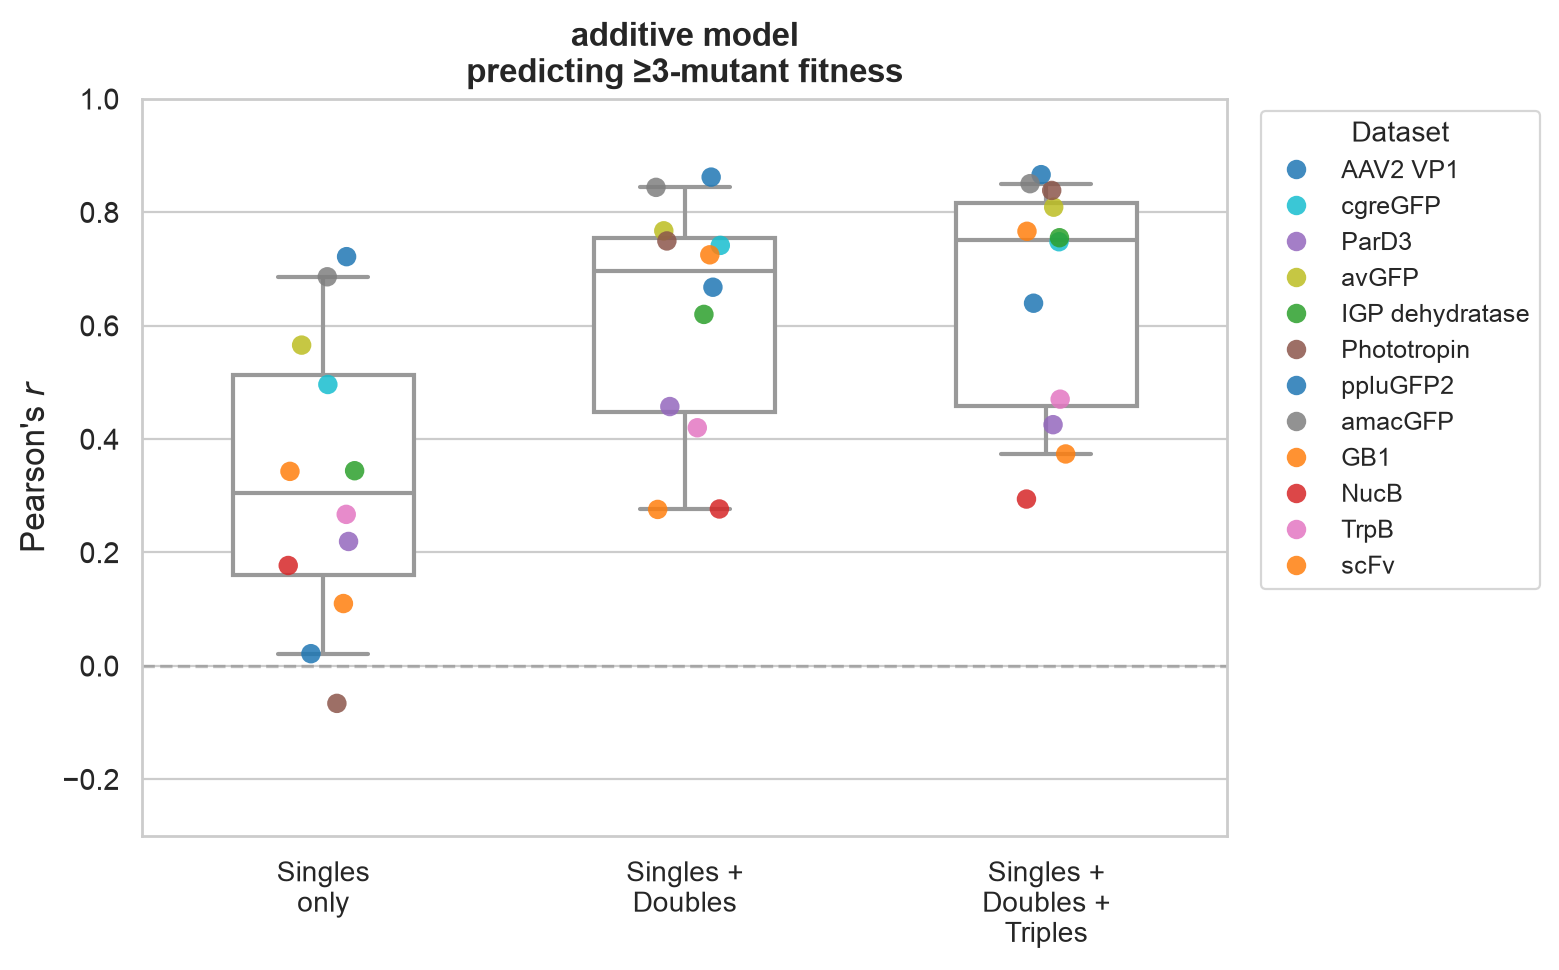


Median Pearson r by training configuration:
  Singles                       : median r = 0.305 (n=12 datasets)
  Singles+Doubles               : median r = 0.696 (n=12 datasets)
  Singles+Doubles+Triples       : median r = 0.751 (n=12 datasets)


In [26]:
# ── Fig. 2E analog: box plot of Pearson r by training configuration ──

FIGURES_DIR = Path('../figures')
FIGURES_DIR.mkdir(exist_ok=True)

order = ['Singles', 'Singles+Doubles', 'Singles+Doubles+Triples']
xticklabels = ['Singles\nonly', 'Singles +\nDoubles', 'Singles +\nDoubles +\nTriples']

datasets = sorted(overall['dataset'].unique())
dataset_palette = dict(zip(datasets, sns.color_palette('tab10', len(datasets))))

fig, ax = plt.subplots(figsize=(8, 5))

sns.boxplot(data=overall, x='training', y='pearson_r', order=order,
            color='white', width=0.5, linewidth=1.5, fliersize=0,
            whis=(5, 95), ax=ax, zorder=2)

sns.stripplot(data=overall, x='training', y='pearson_r', order=order,
              hue='dataset', palette=dataset_palette,
              size=7, jitter=True, dodge=False, alpha=0.85, ax=ax, zorder=3)

ax.set_xticks(range(len(order)))
ax.set_xticklabels(xticklabels, fontsize=10)
ax.set_xlabel('')
ax.set_ylabel("Pearson's $r$", fontsize=12)
ax.set_ylim(-0.3, 1.)
ax.axhline(0, color='gray', linestyle='--', alpha=0.5)
ax.set_title('additive model\npredicting ≥3-mutant fitness',
             fontsize=12, fontweight='bold')
ax.legend(title='Dataset', bbox_to_anchor=(1.02, 1), loc='upper left',
          fontsize=9, title_fontsize=10)

plt.tight_layout()
plt.savefig(FIGURES_DIR / 'fig2e_ridge.pdf', bbox_inches='tight')
plt.show()

print('\nMedian Pearson r by training configuration:')
for config in order:
    subset = overall[overall['training'] == config]
    print(f'  {config:30s}: median r = {subset["pearson_r"].median():.3f} '
          f'(n={len(subset)} datasets)')

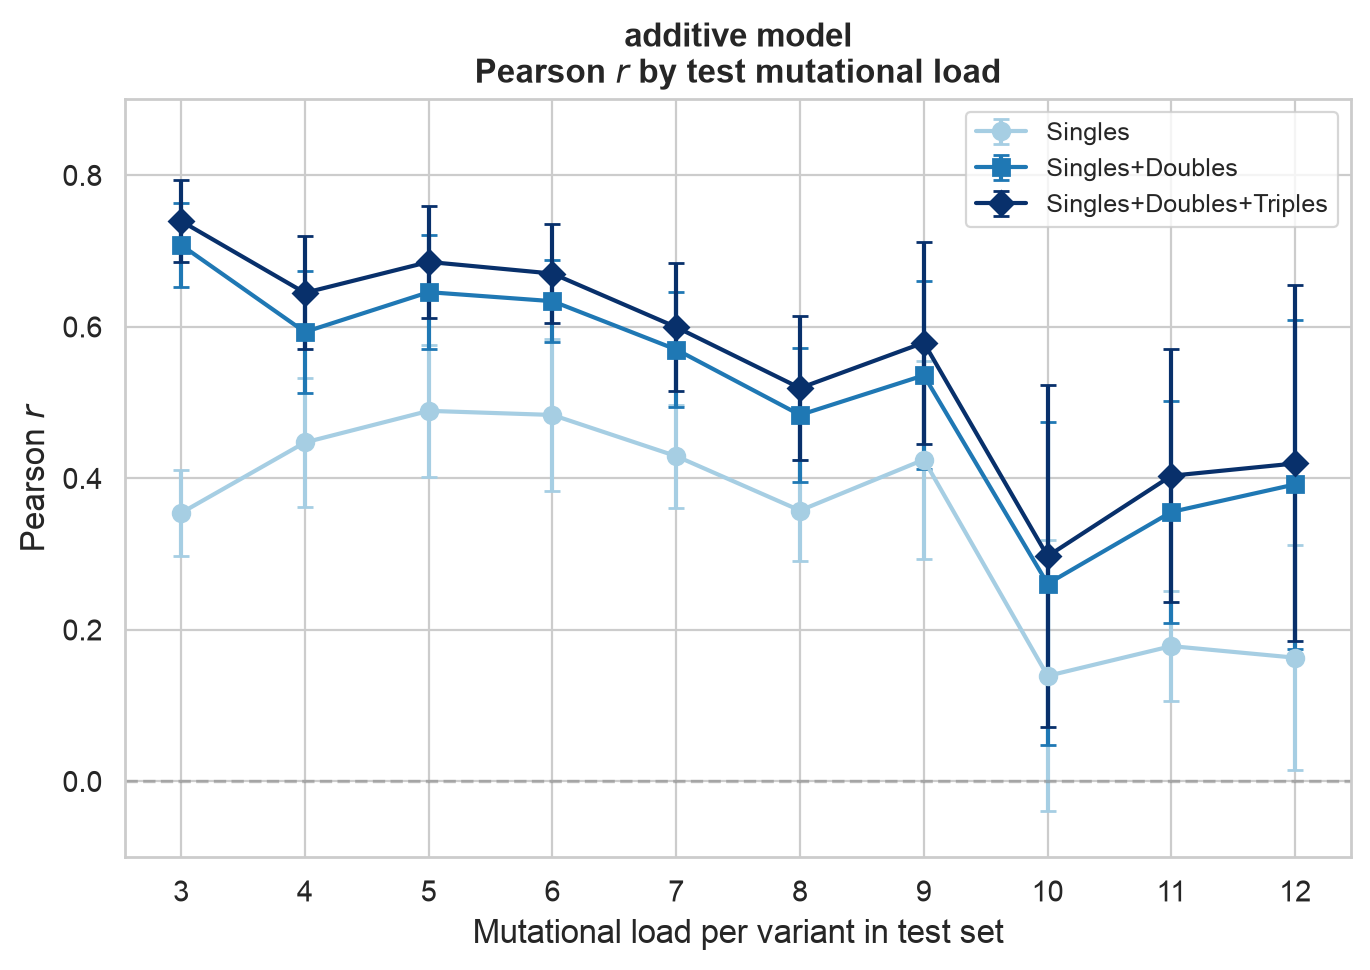

Number of datasets per test mutational load:
  load 3: n=12 datasets
  load 4: n=12 datasets
  load 5: n=9 datasets
  load 6: n=9 datasets
  load 7: n=8 datasets
  load 8: n=8 datasets
  load 9: n=7 datasets
  load 10: n=7 datasets
  load 11: n=5 datasets
  load 12: n=4 datasets


In [27]:
# ── Fig. 2F analog: Pearson r vs test mutational load (3–12) ──

per_load = results_df[results_df['test_mut_load'].notna()].copy()
per_load['test_mut_load'] = per_load['test_mut_load'].astype(int)
per_load = per_load[(per_load['test_mut_load'] >= 3) & (per_load['test_mut_load'] <= 12)]

fig, ax = plt.subplots(figsize=(7, 5))

order = ['Singles', 'Singles+Doubles', 'Singles+Doubles+Triples']
palette = ['#a6cee3', '#1f78b4', '#08306b']
markers = ['o', 's', 'D']

for config, color, marker in zip(order, palette, markers):
    sub = per_load[per_load['training'] == config]
    means = sub.groupby('test_mut_load')['pearson_r'].mean()
    sems = sub.groupby('test_mut_load')['pearson_r'].sem()
    loads = means.index.values
    ax.errorbar(loads, means.values, yerr=sems.values,
                marker=marker, color=color, label=config,
                linewidth=1.5, markersize=6, capsize=3)

ax.set_xlabel('Mutational load per variant in test set', fontsize=12)
ax.set_ylabel('Pearson $r$', fontsize=12)
ax.set_xticks(range(3, 13))
ax.set_ylim(-0.1, 0.9)
ax.legend(fontsize=9)
ax.axhline(0, color='gray', linestyle='--', alpha=0.5)
ax.set_title('additive model\nPearson $r$ by test mutational load',
             fontsize=12, fontweight='bold')

plt.tight_layout()
plt.show()

n_per_load = per_load[per_load['training'] == 'Singles'].groupby('test_mut_load')['dataset'].nunique()
print('Number of datasets per test mutational load:')
for load, n in n_per_load.items():
    print(f'  load {load}: n={n} datasets')


## 5. Fig. S3A analog: Heatmap of correlation by training and test mutational load

Tran et al.’s Fig. S3A shows a heatmap where rows = max training mutational load
(1, 2, 3) and columns = test mutational load (3, 4, 5, …, 23, all).
We reproduce this with ridge regression.  Loads ≤3 are evaluated via 5-fold CV
held-out predictions; loads ≥4 via averaged predictions on the fixed test set.


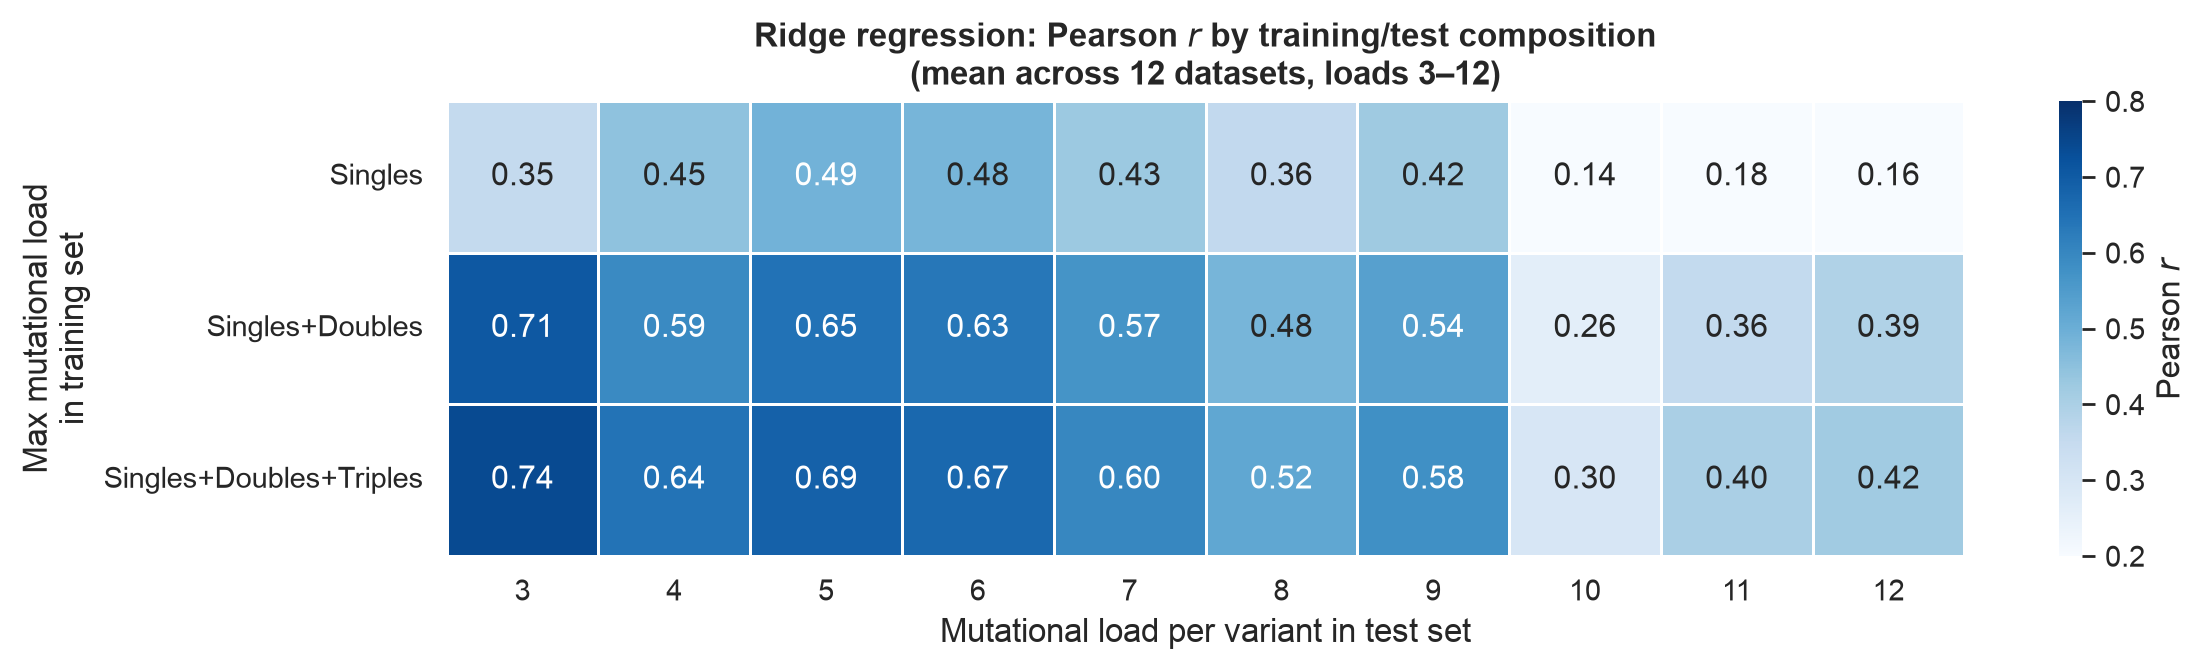

In [28]:
# Build heatmap data: mean Pearson r across datasets

per_load_all = results_df[results_df['test_mut_load'].notna()].copy()
per_load_all['test_mut_load'] = per_load_all['test_mut_load'].astype(int)
per_load_capped = per_load_all[(per_load_all['test_mut_load'] >= 3) &
                               (per_load_all['test_mut_load'] <= 12)]

heatmap_data = per_load_capped.pivot_table(
    values='pearson_r',
    index='max_train_load',
    columns='test_mut_load',
    aggfunc='mean'
)

fig, ax = plt.subplots(figsize=(12, 3.5))

try:
    annot = heatmap_data.map(lambda x: f'{x:.2f}' if pd.notna(x) else '')
except AttributeError:
    annot = heatmap_data.applymap(lambda x: f'{x:.2f}' if pd.notna(x) else '')

sns.heatmap(heatmap_data, annot=annot, fmt='', cmap='Blues',
            vmin=0.2, vmax=0.8, ax=ax,
            cbar_kws={'label': 'Pearson $r$'},
            linewidths=0.5, linecolor='white')

ax.set_xlabel('Mutational load per variant in test set', fontsize=12)
ax.set_ylabel('Max mutational load\nin training set', fontsize=12)
ax.set_yticklabels(['Singles', 'Singles+Doubles', 'Singles+Doubles+Triples'],
                   rotation=0)
ax.set_title(f'Ridge regression: Pearson $r$ by training/test composition\n'
             f'(mean across {per_load_capped["dataset"].nunique()} datasets, loads 3\u201312)',
             fontsize=12, fontweight='bold')

plt.tight_layout()
plt.show()


## 6. Per-dataset results

Show the improvement from singles → singles+doubles for each dataset.


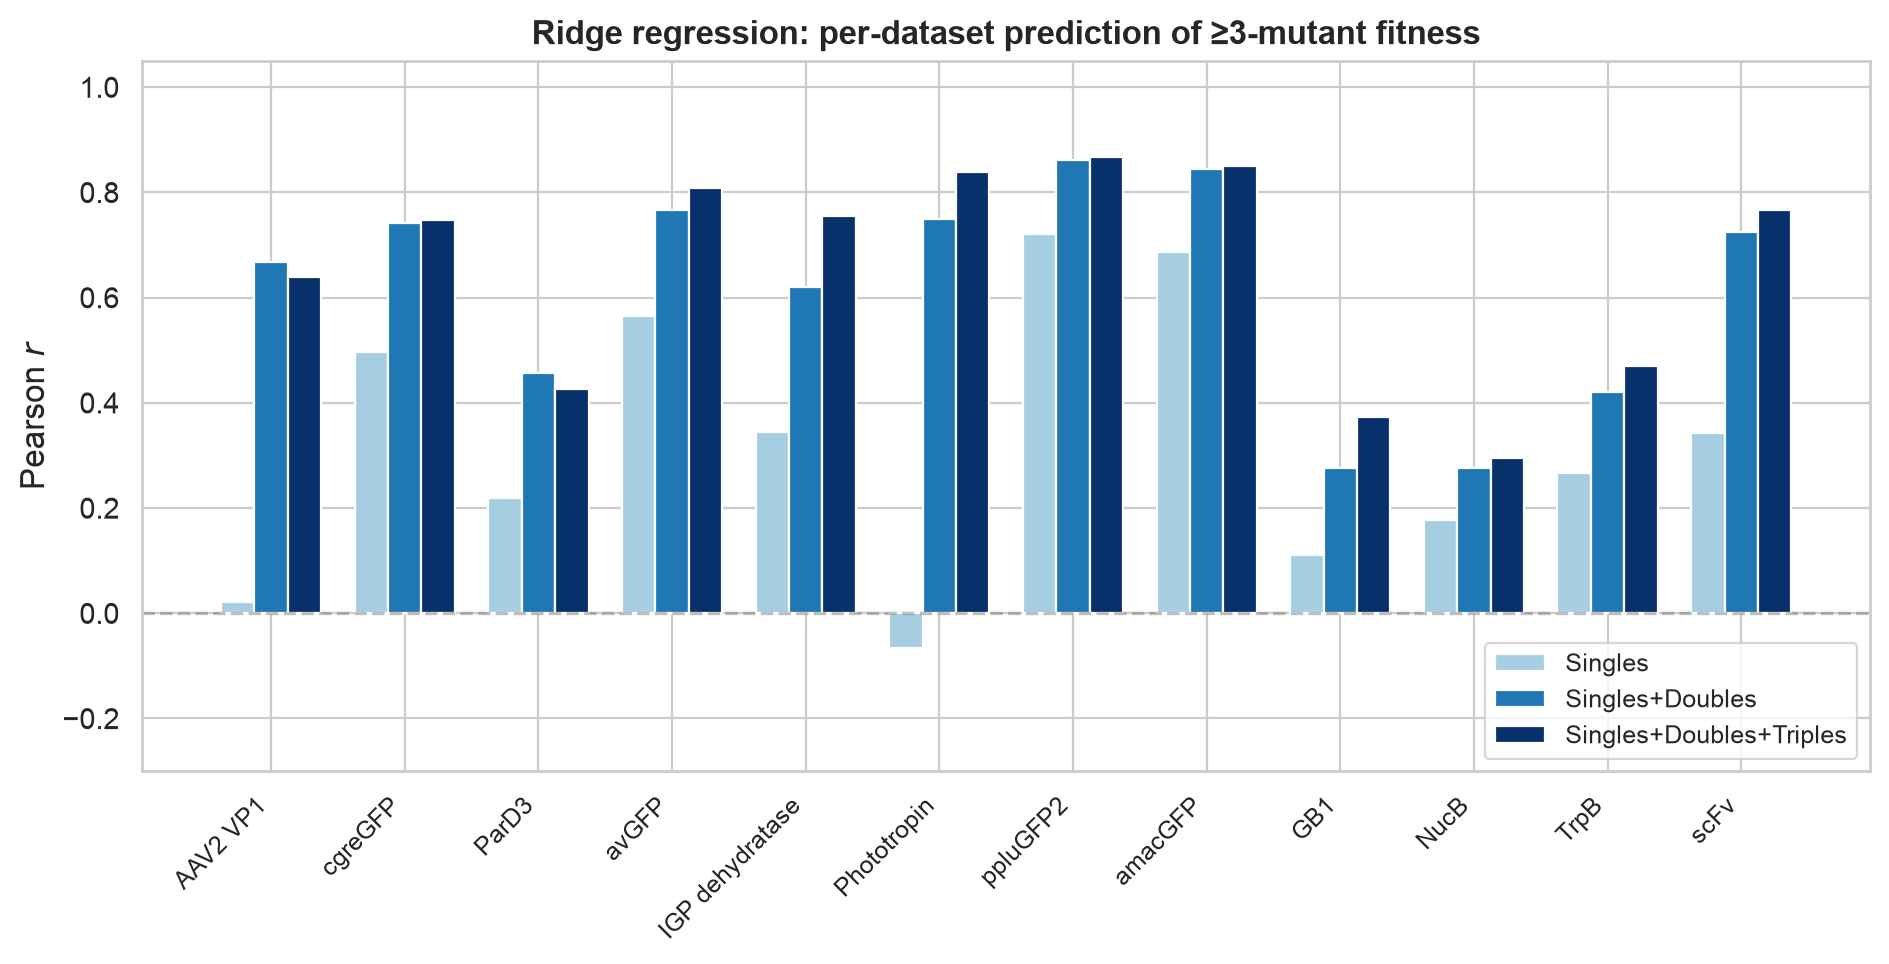

In [29]:
# Per-dataset comparison
datasets_list = overall['dataset'].unique()
n_datasets = len(datasets_list)

if n_datasets > 0:
    fig, ax = plt.subplots(figsize=(max(8, n_datasets * 0.8), 5))
    x = np.arange(n_datasets)
    width = 0.25
    for i, (config, color) in enumerate(zip(order, palette)):
        vals = []
        for ds in datasets_list:
            row = overall[(overall['dataset'] == ds) & (overall['training'] == config)]
            vals.append(row['pearson_r'].values[0] if len(row) > 0 else np.nan)
        ax.bar(x + i * width, vals, width, label=config, color=color, edgecolor='white')
    ax.set_xticks(x + width)
    ax.set_xticklabels(datasets_list, rotation=45, ha='right', fontsize=9)
    ax.set_ylabel('Pearson $r$', fontsize=12)
    ax.set_title('Ridge regression: per-dataset prediction of \u22653-mutant fitness',
                 fontsize=12, fontweight='bold')
    ax.legend(fontsize=9, loc='lower right')
    ax.set_ylim(-0.3, 1.05)
    ax.axhline(0, color='gray', linestyle='--', alpha=0.5)
    plt.tight_layout()
    plt.show()


## 7. Summary

The key finding: **ridge regression—a purely additive model with zero capacity
for epistasis—reproduces the Fig. 2E/F pattern.**

Adding doubles and triples to training improves prediction of higher-order
mutants, not because the model learns epistatic interactions, but because
additional observations reduce the variance of the additive coefficient
estimates (Gauss–Markov theorem).

### Protocol notes
- We follow the Tran et al. protocol: 5-fold CV on variants with 1–3
  mutations; variants with ≥4 mutations form a fixed test set.
- Predictions are evaluated at each mutational load from 3 upward, matching
  the Fig. S3A heatmap.  Load-3 predictions come from CV held-out folds;
  load ≥4 predictions are averaged across folds.
- The improvement from singles → singles+doubles → +triples is a
  **variance-reduction** effect, not epistasis learning:
  - With singles only, each additive effect is estimated from one observation.
  - Adding doubles provides redundant measurements of the same additive effects.
  - More data → lower estimator variance → better extrapolation.


In [30]:
# Final summary table
if len(overall) > 0:
    summary = overall.groupby('training').agg(
        n_datasets=('dataset', 'nunique'),
        mean_pearson=('pearson_r', 'mean'),
        median_pearson=('pearson_r', 'median'),
        std_pearson=('pearson_r', 'std'),
    ).reindex(order)

    print('=== Ridge Regression Benchmarking Summary ===')
    print('(Additive model, no epistasis capacity)\n')
    print(summary.to_string(float_format='%.3f'))
    print('\nConclusion: The improvement from adding doubles/triples to training')
    print('is fully reproduced by a linear model.  No epistasis learning required.')
else:
    print('No results to summarize. Run the benchmarking cells above first.')


=== Ridge Regression Benchmarking Summary ===
(Additive model, no epistasis capacity)

                         n_datasets  mean_pearson  median_pearson  std_pearson
training                                                                      
Singles                          12         0.324           0.305        0.253
Singles+Doubles                  12         0.617           0.696        0.208
Singles+Doubles+Triples          12         0.653           0.751        0.206

Conclusion: The improvement from adding doubles/triples to training
is fully reproduced by a linear model.  No epistasis learning required.


## 8. Comparison with MULTI-evolve (Table S3)

Load the MULTI-evolve benchmarking results from Table S3 (training composition
and encodings) and compare directly with our ridge regression baseline.

Table S3 contains results for 7 encodings; only One-hot is tested across all
3 training loads (1=Singles, 2=+Doubles, 3=+Triples).  The other encodings
(PLM embeddings, AAidx, Georgiev) are only tested at training load 2.

In [31]:
# Load MULTI-evolve Table S3 results
table_s3 = pd.read_excel(
    '../data/Table S3 MULTI-evolve benchmarking training composition and encodings.xlsx',
    sheet_name=0
)

# Rename columns to match our convention
table_s3 = table_s3.rename(columns={
    'Dataset Name': 'dataset',
    'Training Load': 'max_train_load',
    'Feature': 'feature',
    'Pearson - Test': 'pearson_r',
    'Spearman - Test': 'spearman_r',
    'Number of Layers': 'num_layers',
    'Layer Size': 'layer_size',
})

# Map max_train_load to training config labels
train_label_map = {1: 'Singles', 2: 'Singles+Doubles', 3: 'Singles+Doubles+Triples'}
table_s3['training'] = table_s3['max_train_load'].map(train_label_map)

print(f'Table S3: {len(table_s3)} rows, {table_s3["dataset"].nunique()} datasets')
print(f'Encodings: {sorted(table_s3["feature"].unique())}')
print(f'Training loads per encoding:')
for feat in sorted(table_s3['feature'].unique()):
    loads = sorted(table_s3[table_s3['feature'] == feat]['max_train_load'].unique())
    print(f'  {feat}: loads {loads}')

# One-hot is the only encoding tested across all 3 training loads
# This is the direct comparison to our ridge baseline
me_onehot = table_s3[table_s3['feature'] == 'One-hot'].copy()
me_overall = me_onehot.copy()  # for compatibility with downstream cells

# Also keep all encodings at training load 2 for broader comparison
me_all_enc_load2 = table_s3[table_s3['max_train_load'] == 2].copy()

print(f'\nOne-hot rows: {len(me_onehot)} ({me_onehot["dataset"].nunique()} datasets × '
      f'{me_onehot["max_train_load"].nunique()} loads)')
print(f'\nOne-hot Pearson medians per training load:')
for tl in [1, 2, 3]:
    sub = me_onehot[me_onehot['max_train_load'] == tl]
    print(f'  {train_label_map[tl]:30s}: median r = {sub["pearson_r"].median():.3f} (n={len(sub)})')

Table S3: 108 rows, 12 datasets
Encodings: ['AAidx', 'Ankh Large', 'ESM2-15B', 'ESM2-3B', 'Georgiev', 'One-hot', 'ProtT5-XL']
Training loads per encoding:
  AAidx: loads [2]
  Ankh Large: loads [2]
  ESM2-15B: loads [2]
  ESM2-3B: loads [2]
  Georgiev: loads [2]
  One-hot: loads [1, 2, 3]
  ProtT5-XL: loads [2]

One-hot rows: 36 (12 datasets × 3 loads)

One-hot Pearson medians per training load:
  Singles                       : median r = 0.122 (n=12)
  Singles+Doubles               : median r = 0.618 (n=12)
  Singles+Doubles+Triples       : median r = 0.772 (n=12)


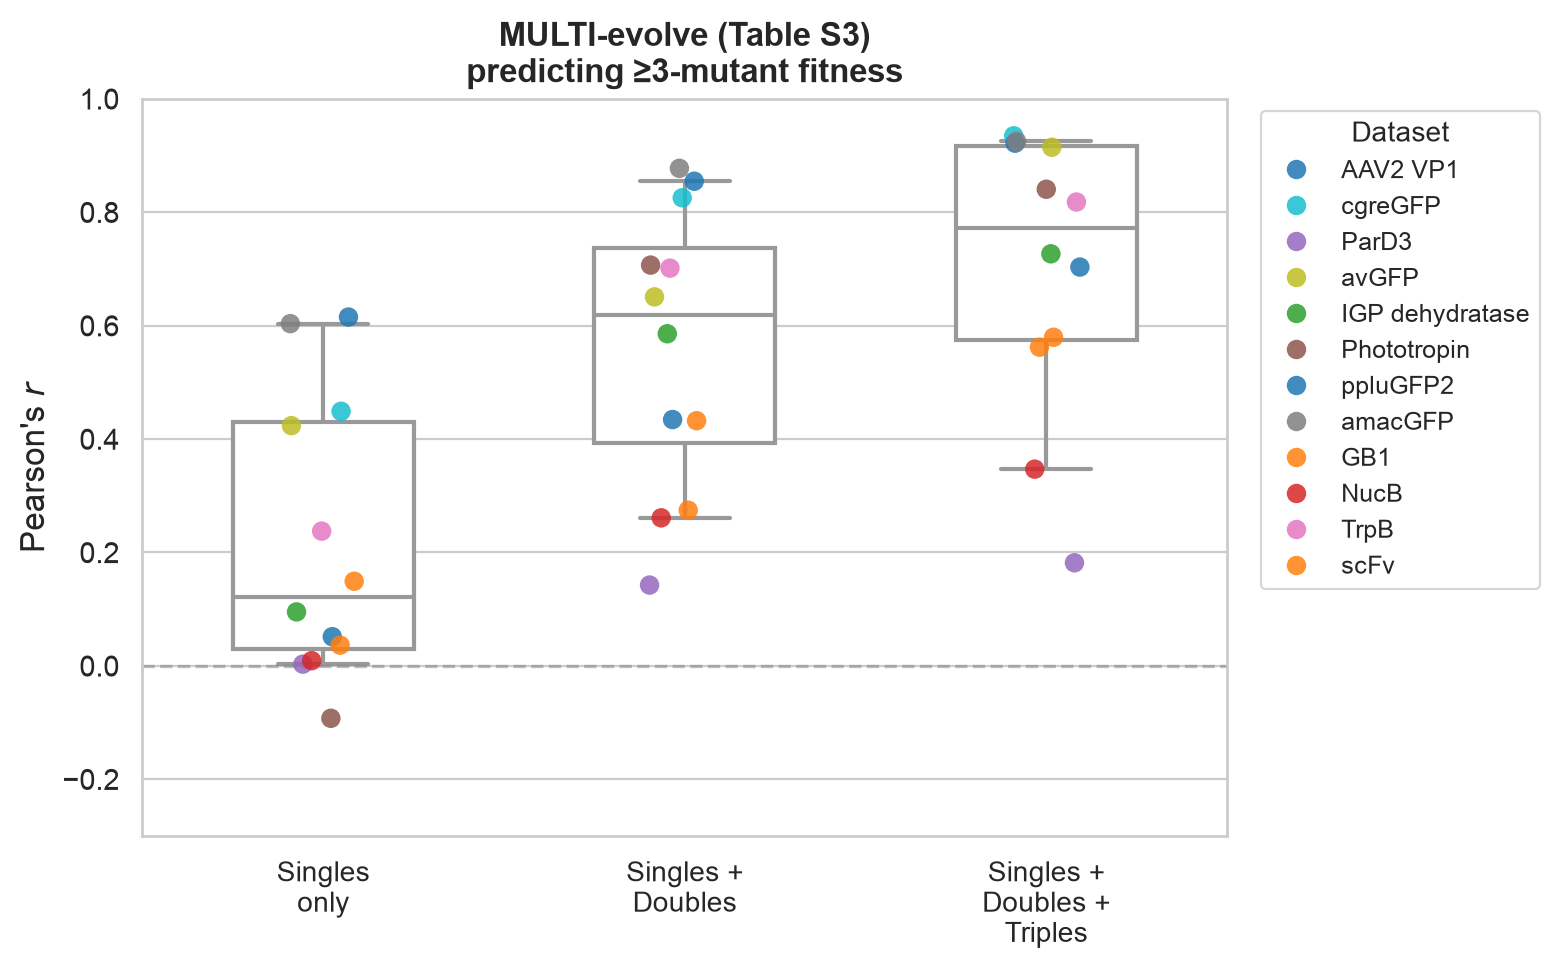


Median Pearson r by training configuration (MULTI-evolve):
  Singles                       : median r = 0.122 (n=12 datasets)
  Singles+Doubles               : median r = 0.618 (n=12 datasets)
  Singles+Doubles+Triples       : median r = 0.772 (n=12 datasets)


In [32]:
# ── MULTI-evolve Fig. 2E (from Table S3 One-hot results) ──

fig, ax = plt.subplots(figsize=(8, 5))

sns.boxplot(data=me_onehot, x='training', y='pearson_r', order=order,
            color='white', width=0.5, linewidth=1.5, fliersize=0,
            whis=(5, 95), ax=ax, zorder=2)

sns.stripplot(data=me_onehot, x='training', y='pearson_r', order=order,
              hue='dataset', palette=dataset_palette,
              size=7, jitter=True, dodge=False, alpha=0.85, ax=ax, zorder=3)

ax.set_xticks(range(len(order)))
ax.set_xticklabels(xticklabels, fontsize=10)
ax.set_xlabel('')
ax.set_ylabel("Pearson's $r$", fontsize=12)
ax.set_ylim(-0.3, 1.)
ax.axhline(0, color='gray', linestyle='--', alpha=0.5)
ax.set_title('MULTI-evolve (Table S3)\npredicting ≥3-mutant fitness',
             fontsize=12, fontweight='bold')
ax.legend(title='Dataset', bbox_to_anchor=(1.02, 1), loc='upper left',
          fontsize=9, title_fontsize=10)

plt.tight_layout()
plt.savefig(FIGURES_DIR / 'fig2e_multievolve.pdf', bbox_inches='tight')
plt.show()

print('\nMedian Pearson r by training configuration (MULTI-evolve):')
for config in order:
    subset = me_onehot[me_onehot['training'] == config]
    print(f'  {config:30s}: median r = {subset["pearson_r"].median():.3f} '
          f'(n={len(subset)} datasets)')

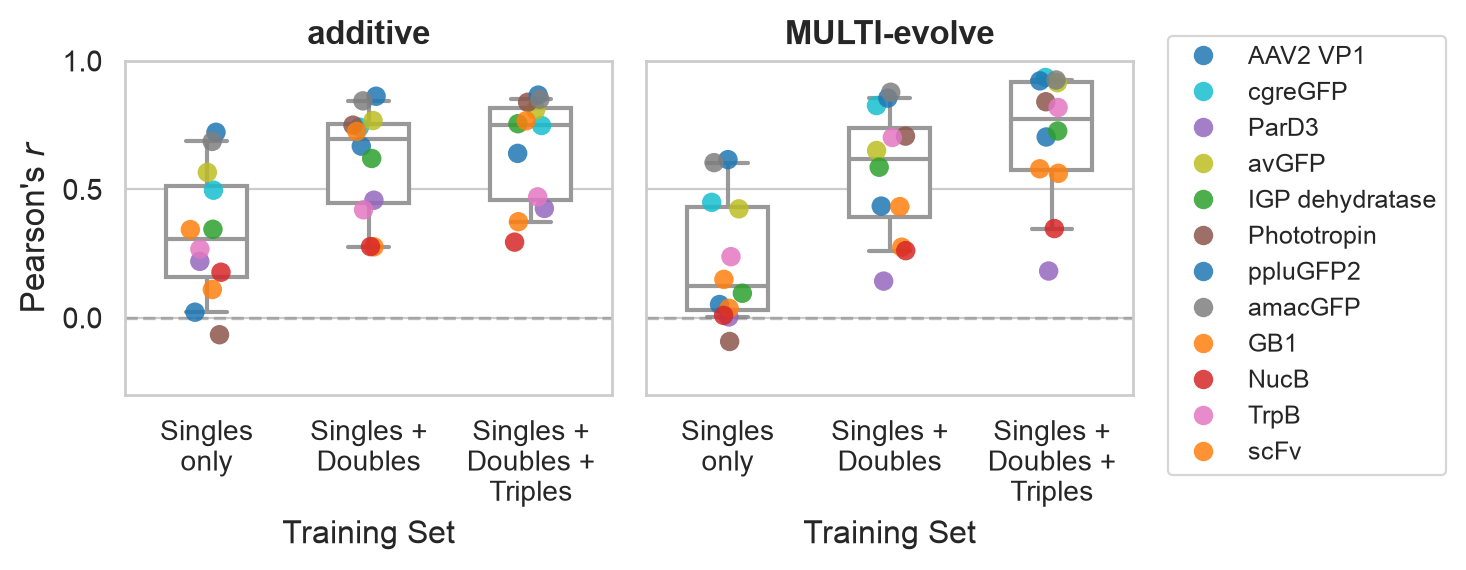

In [33]:
# ── Side-by-side: additive vs MULTI-evolve (Pearson) ──

fig, axes = plt.subplots(1, 2, figsize=(6, 3), sharey=True)

for ax, (data, title) in zip(axes, [
    (overall, 'additive'),
    (me_onehot, 'MULTI-evolve')
]):
    sns.boxplot(data=data, x='training', y='pearson_r', order=order,
                color='white', width=0.5, linewidth=1.5, fliersize=0,
                whis=(5, 95), ax=ax, zorder=2)
    sns.stripplot(data=data, x='training', y='pearson_r', order=order,
                  hue='dataset', palette=dataset_palette,
                  size=7, jitter=True, dodge=False, alpha=0.85, ax=ax, zorder=3)
    ax.set_xticks(range(len(order)))
    ax.set_xticklabels(xticklabels, fontsize=10)
    ax.set_xlabel('Training Set')
    ax.set_ylabel("Pearson's $r$" if ax == axes[0] else '', fontsize=12)
    ax.set_ylim(-0.3, 1.)
    ax.axhline(0, color='gray', linestyle='--', alpha=0.5)
    ax.set_title(title, fontsize=12, fontweight='bold')
    if ax.get_legend():
        ax.get_legend().remove()

handles, labels_leg = axes[1].get_legend_handles_labels()
fig.legend(handles, labels_leg,
           bbox_to_anchor=(0.99, 0.55), loc='center left',
           fontsize=9, title_fontsize=10)

plt.tight_layout()
plt.savefig(FIGURES_DIR / 'fig2e_comparison.pdf', bbox_inches='tight')
plt.show()

Matched comparisons: 36 (datasets × training configs)


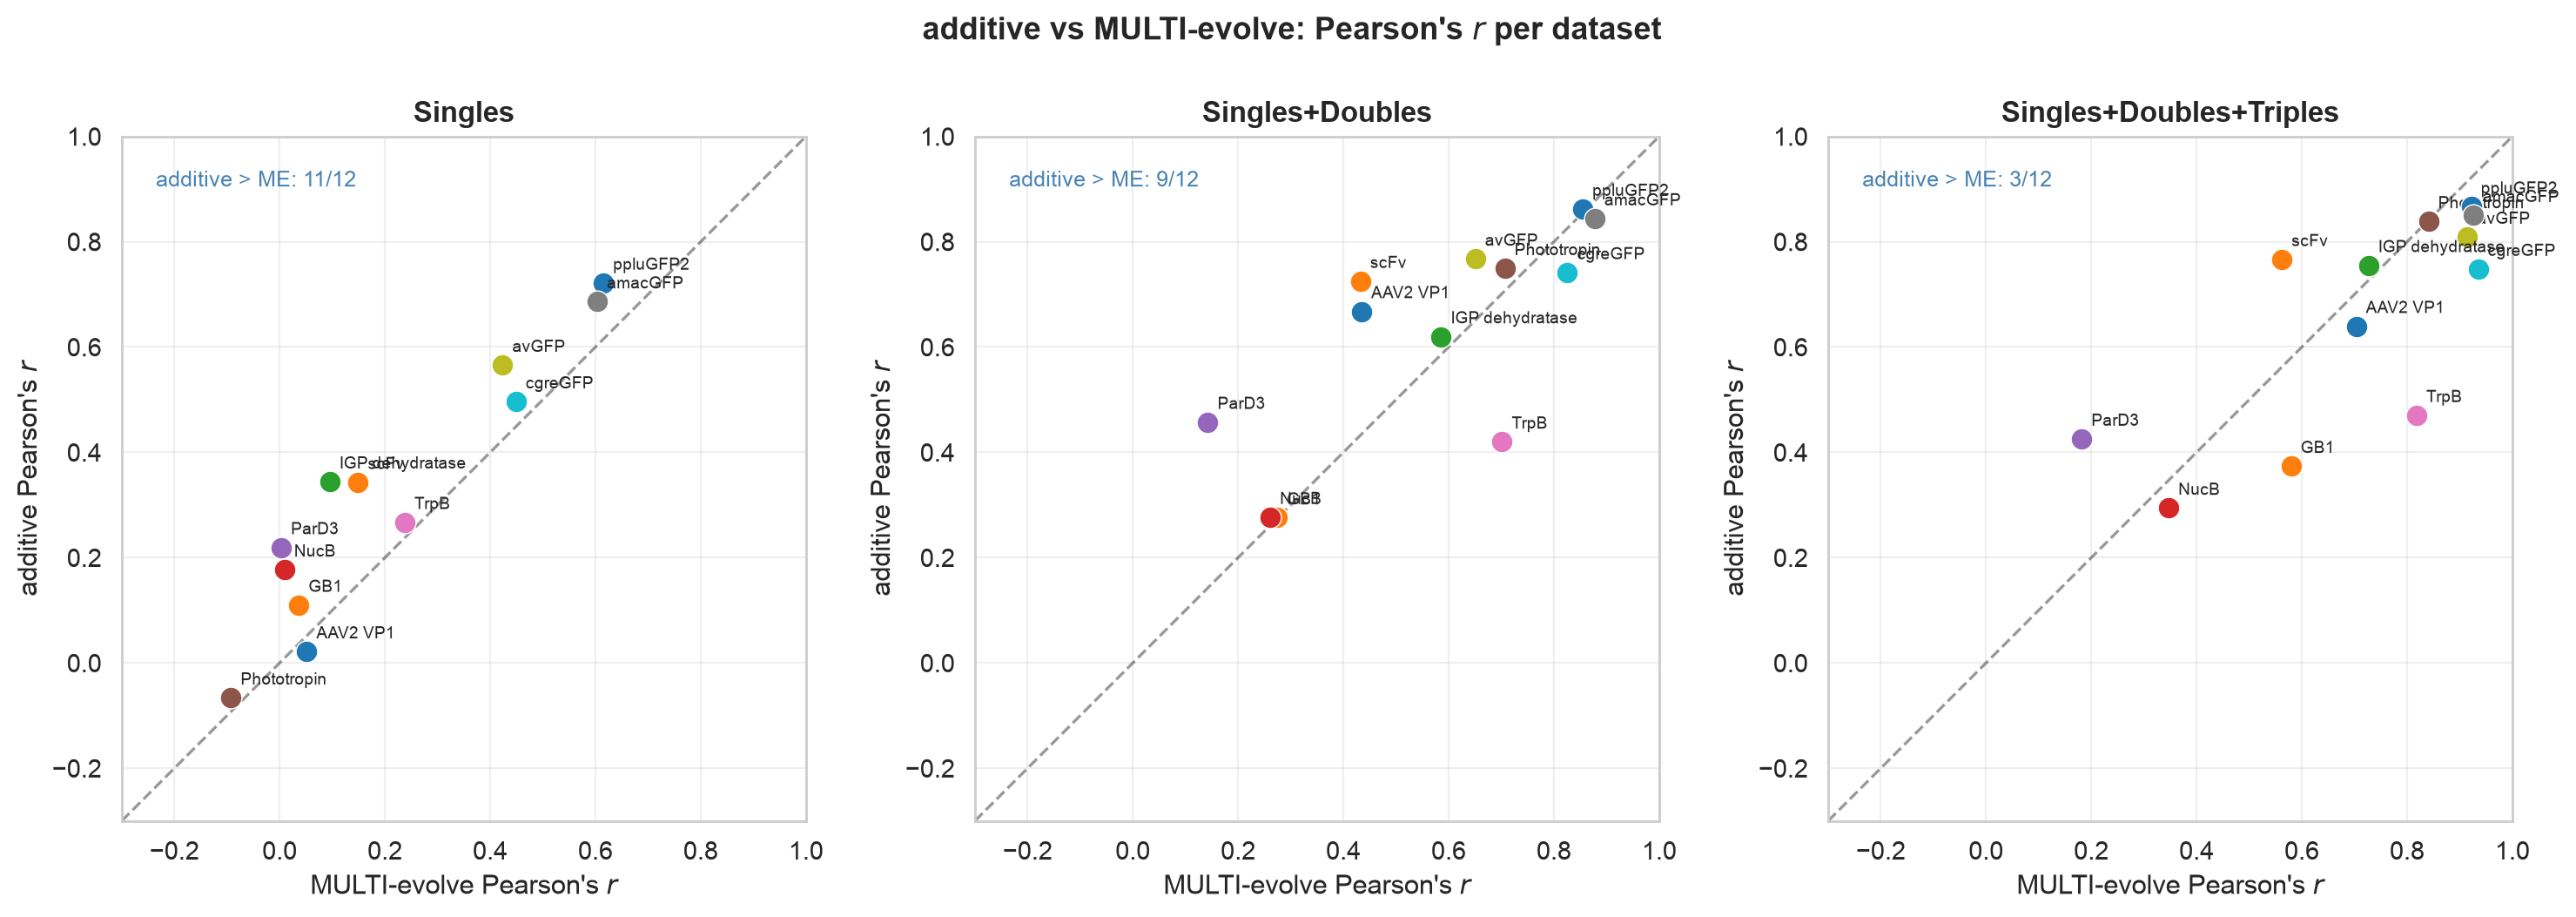


── Summary ──

Singles:
  Mean additive r:  0.324
  Mean ME r:     0.215
  Mean diff:     +0.109
  additive wins:    11/12

Singles+Doubles:
  Mean additive r:  0.617
  Mean ME r:     0.562
  Mean diff:     +0.055
  additive wins:    9/12

Singles+Doubles+Triples:
  Mean additive r:  0.653
  Mean ME r:     0.705
  Mean diff:     -0.052
  additive wins:    3/12


In [34]:
# ── Scatter: additive r vs MULTI-evolve r per dataset (Pearson) ──

# Merge overall results
ridge_ov = overall[['dataset', 'training', 'pearson_r']].rename(
    columns={'pearson_r': 'additive_r'})
me_ov = me_onehot[['dataset', 'training', 'pearson_r']].rename(
    columns={'pearson_r': 'me_r'})

comparison = ridge_ov.merge(me_ov, on=['dataset', 'training'], how='inner')
print(f'Matched comparisons: {len(comparison)} (datasets × training configs)')

fig, axes = plt.subplots(1, 3, figsize=(15, 5))

for ax, config in zip(axes, order):
    sub = comparison[comparison['training'] == config]

    for _, row in sub.iterrows():
        ax.scatter(row['me_r'], row['additive_r'],
                   color=dataset_palette[row['dataset']],
                   s=80, zorder=3, edgecolors='white', linewidth=0.5)
        ax.annotate(row['dataset'], (row['me_r'], row['additive_r']),
                    fontsize=7, ha='left', va='bottom',
                    xytext=(4, 4), textcoords='offset points')

    lims = [-0.3, 1.0]
    ax.plot(lims, lims, 'k--', alpha=0.4, zorder=1)
    ax.set_xlim(lims)
    ax.set_ylim(lims)
    ax.set_xlabel("MULTI-evolve Pearson's $r$", fontsize=11)
    ax.set_ylabel("additive Pearson's $r$", fontsize=11)
    ax.set_title(config, fontsize=12, fontweight='bold')
    ax.set_aspect('equal')
    ax.grid(True, alpha=0.3)

    n_above = (sub['additive_r'] > sub['me_r']).sum()
    ax.text(0.05, 0.95, f'additive > ME: {n_above}/{len(sub)}',
            transform=ax.transAxes, fontsize=9, va='top', color='steelblue')

plt.suptitle("additive vs MULTI-evolve: Pearson's $r$ per dataset",
             fontsize=13, fontweight='bold', y=1.02)
plt.tight_layout()
plt.savefig(FIGURES_DIR / 'ridge_vs_multievolve_scatter.pdf', bbox_inches='tight')
plt.show()

# Summary stats
print('\n── Summary ──')
for config in order:
    sub = comparison[comparison['training'] == config]
    diff = sub['additive_r'] - sub['me_r']
    print(f'\n{config}:')
    print(f'  Mean additive r:  {sub["additive_r"].mean():.3f}')
    print(f'  Mean ME r:     {sub["me_r"].mean():.3f}')
    print(f'  Mean diff:     {diff.mean():+.3f}')
    print(f'  additive wins:    {(diff > 0).sum()}/{len(sub)}')

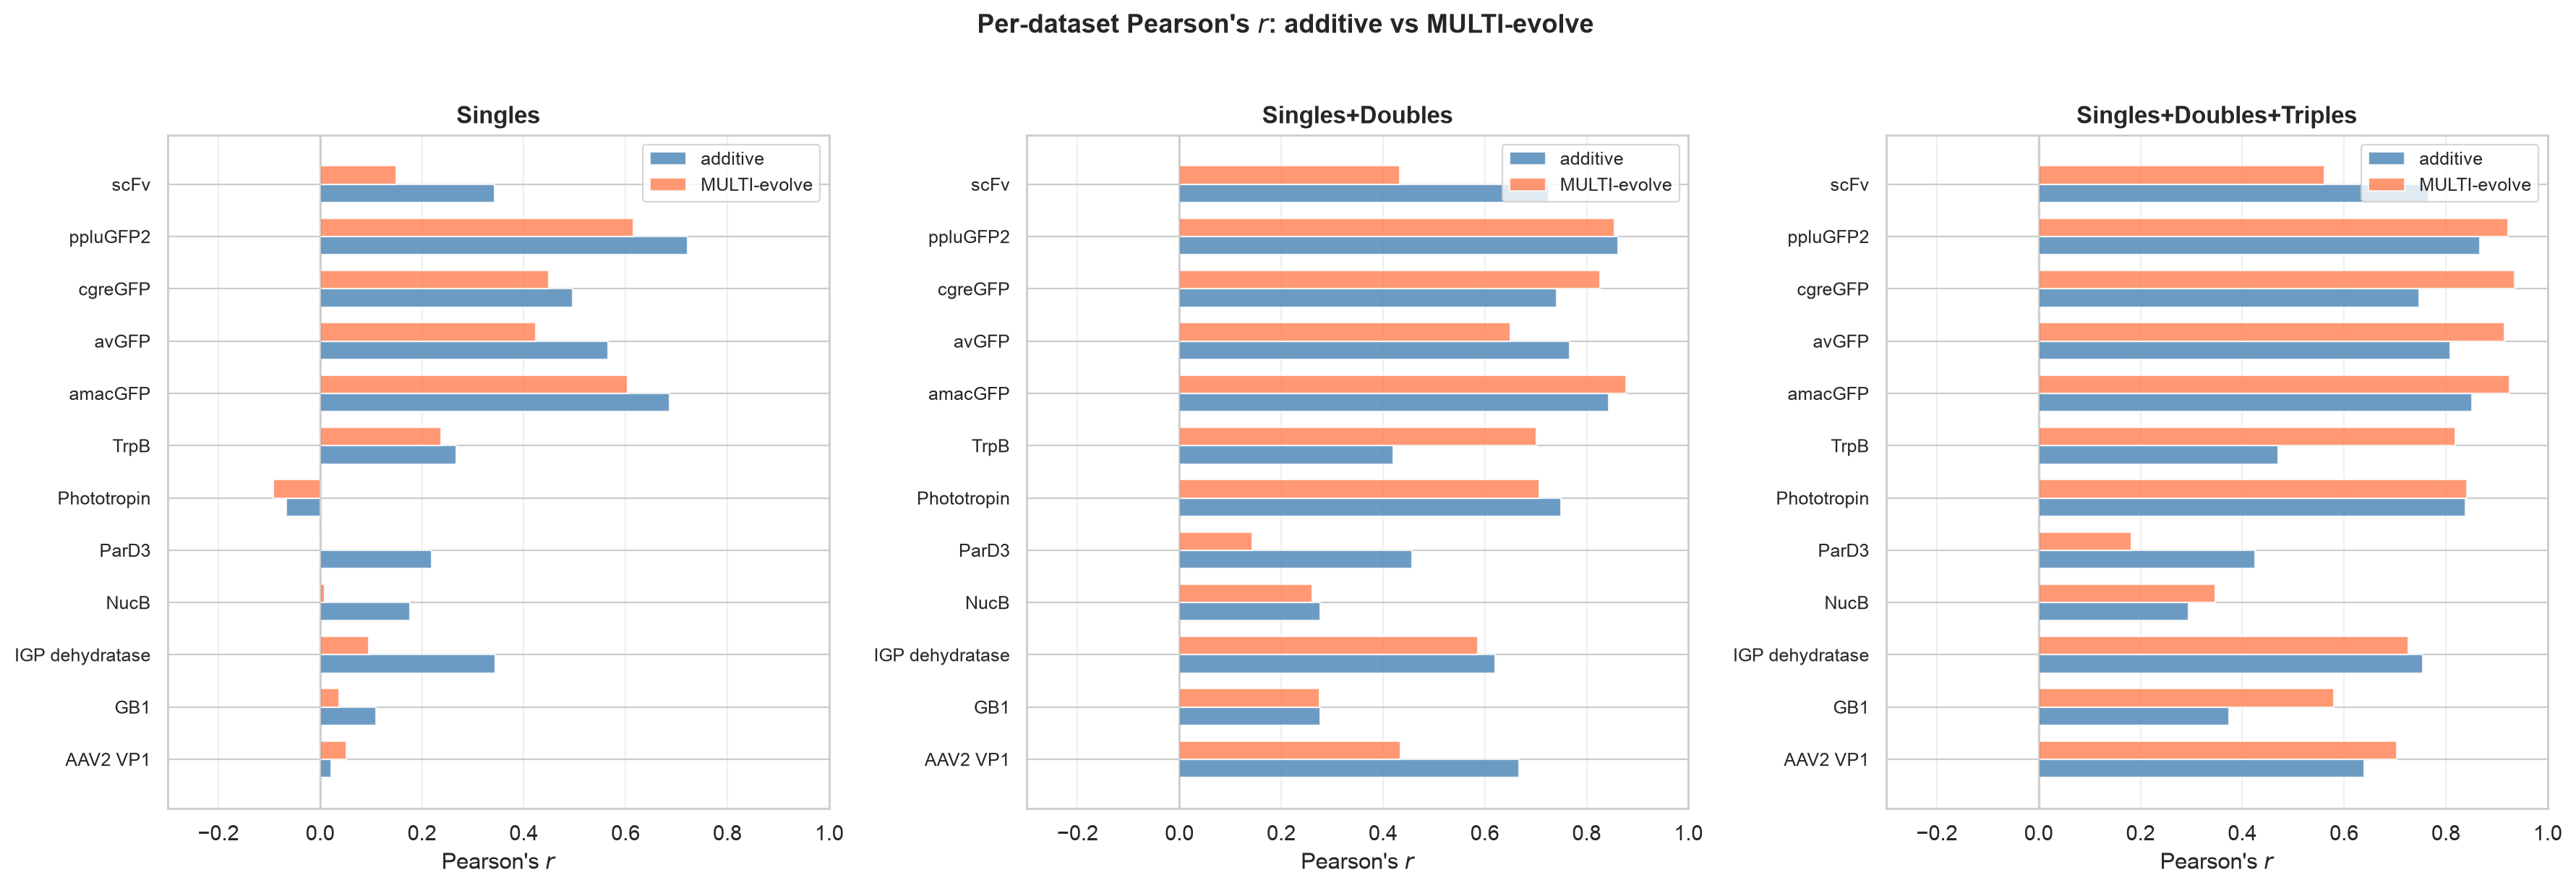

In [35]:
# ── Paired bar chart: additive vs MULTI-evolve per dataset (Pearson) ──

fig, axes = plt.subplots(1, 3, figsize=(18, 6))

for ax, config in zip(axes, order):
    sub = comparison[comparison['training'] == config].sort_values('dataset')
    x = np.arange(len(sub))
    width = 0.35

    ax.barh(x - width/2, sub['additive_r'], width, label='additive',
            color='steelblue', alpha=0.8)
    ax.barh(x + width/2, sub['me_r'], width, label='MULTI-evolve',
            color='coral', alpha=0.8)

    ax.set_yticks(x)
    ax.set_yticklabels(sub['dataset'], fontsize=9)
    ax.set_xlabel("Pearson's $r$", fontsize=11)
    ax.set_title(config, fontsize=12, fontweight='bold')
    ax.legend(fontsize=9)
    ax.set_xlim(-0.3, 1.0)
    ax.axvline(0, color='gray', linestyle='-', alpha=0.3)
    ax.grid(True, axis='x', alpha=0.3)

plt.suptitle("Per-dataset Pearson's $r$: additive vs MULTI-evolve",
             fontsize=13, fontweight='bold', y=1.02)
plt.tight_layout()
plt.savefig(FIGURES_DIR / 'ridge_vs_multievolve_bars.pdf', bbox_inches='tight')
plt.show()

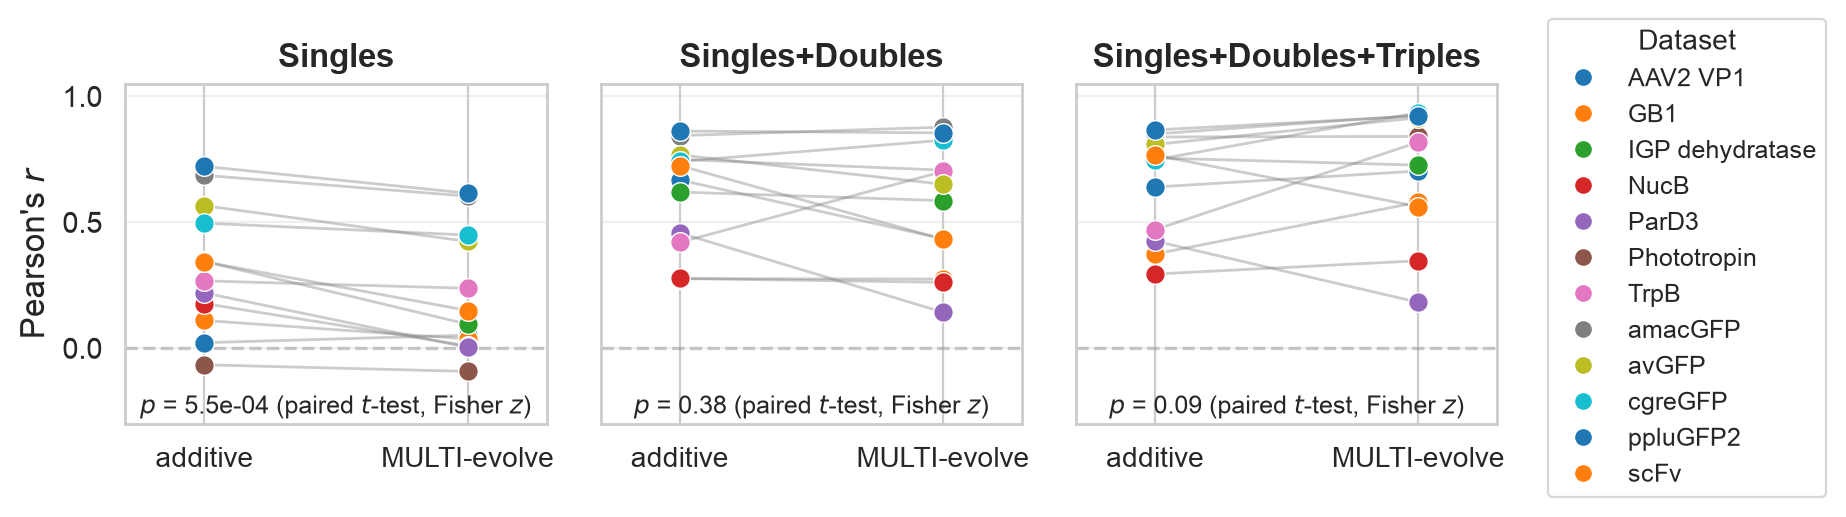


── Paired t-test on Fisher z = arctanh(r) (same datasets, different methods) ──
Singles: n=12, t=4.807, p=0.0005, mean diff r=+0.109, mean diff z=+0.129
Singles+Doubles: n=12, t=0.914, p=0.3802, mean diff r=+0.055, mean diff z=+0.067
Singles+Doubles+Triples: n=12, t=-1.878, p=0.0872, mean diff r=-0.052, mean diff z=-0.182


In [36]:
# ── Paired dot plot: additive vs MULTI-evolve, stratified by training load ──
# Points show Pearson r; the paired t-test is run on Fisher z = arctanh(r).
from scipy.stats import ttest_rel

def fisher_z(r):
    r = np.asarray(r, dtype=float)
    if np.any(~np.isfinite(r)) or np.any(np.abs(r) >= 1):
        raise ValueError(f'Fisher z undefined for r values: {r[~np.isfinite(r) | (np.abs(r) >= 1)]}')
    return np.arctanh(r)

fig, axes = plt.subplots(1, 3, figsize=(8, 2.5), sharey=True)

for ax, config in zip(axes, order):
    sub = comparison[comparison['training'] == config].sort_values('dataset')
    ridge_vals = sub['additive_r'].values
    me_vals = sub['me_r'].values
    datasets_here = sub['dataset'].values

    # Lines connecting paired observations
    for rv, mv in zip(ridge_vals, me_vals):
        ax.plot([0, 1], [rv, mv], color='gray', alpha=0.4, linewidth=1, zorder=1)

    # Points colored by dataset (same palette as other plots)
    for rv, mv, ds in zip(ridge_vals, me_vals, datasets_here):
        ax.scatter(0, rv, color=dataset_palette[ds], s=50, zorder=3,
                   edgecolors='white', linewidth=0.5)
        ax.scatter(1, mv, color=dataset_palette[ds], s=50, zorder=3,
                   edgecolors='white', linewidth=0.5)

    # Paired t-test on Fisher z-transformed correlations
    stat, pval = ttest_rel(fisher_z(ridge_vals), fisher_z(me_vals))
    if pval < 0.001:
        pstr = f'$p$ = {pval:.1e} (paired $t$-test, Fisher $z$)'
    elif pval < 0.01:
        pstr = f'$p$ = {pval:.3f} (paired $t$-test, Fisher $z$)'
    else:
        pstr = f'$p$ = {pval:.2f} (paired $t$-test, Fisher $z$)'
    ax.text(0.5, 0.01, pstr, ha='center', va='bottom', fontsize=9,
            transform=ax.transAxes)

    ax.set_xticks([0, 1])
    ax.set_xticklabels(['additive', 'MULTI-evolve'], fontsize=10)
    ax.set_xlim(-0.3, 1.3)
    ax.set_title(config, fontsize=12, fontweight='bold')
    if ax == axes[0]:
        ax.set_ylabel("Pearson's $r$", fontsize=12)
    ax.set_ylim(-0.3, 1.05)
    ax.axhline(0, color='gray', linestyle='--', alpha=0.4)
    ax.grid(True, axis='y', alpha=0.3)

# Dataset legend (shared)
from matplotlib.lines import Line2D
handles = [Line2D([0], [0], marker='o', color='w', markerfacecolor=dataset_palette[d],
                  markersize=7, label=d) for d in sorted(dataset_palette.keys())]
fig.legend(handles=handles, title='Dataset', bbox_to_anchor=(0.99, 0.5),
           loc='center left', fontsize=9, title_fontsize=10)

plt.tight_layout()
plt.savefig(FIGURES_DIR / 'ridge_vs_multievolve_paired.pdf', bbox_inches='tight')
plt.show()

# Print stats
print('\n── Paired t-test on Fisher z = arctanh(r) (same datasets, different methods) ──')
for config in order:
    rv = comparison.loc[comparison['training'] == config, 'additive_r'].values
    mv = comparison.loc[comparison['training'] == config, 'me_r'].values
    stat, pval = ttest_rel(fisher_z(rv), fisher_z(mv))
    print(f'{config}: n={len(rv)}, t={stat:.3f}, p={pval:.4f}, '
          f'mean diff r={(rv - mv).mean():+.3f}, '
          f'mean diff z={(fisher_z(rv) - fisher_z(mv)).mean():+.3f}')

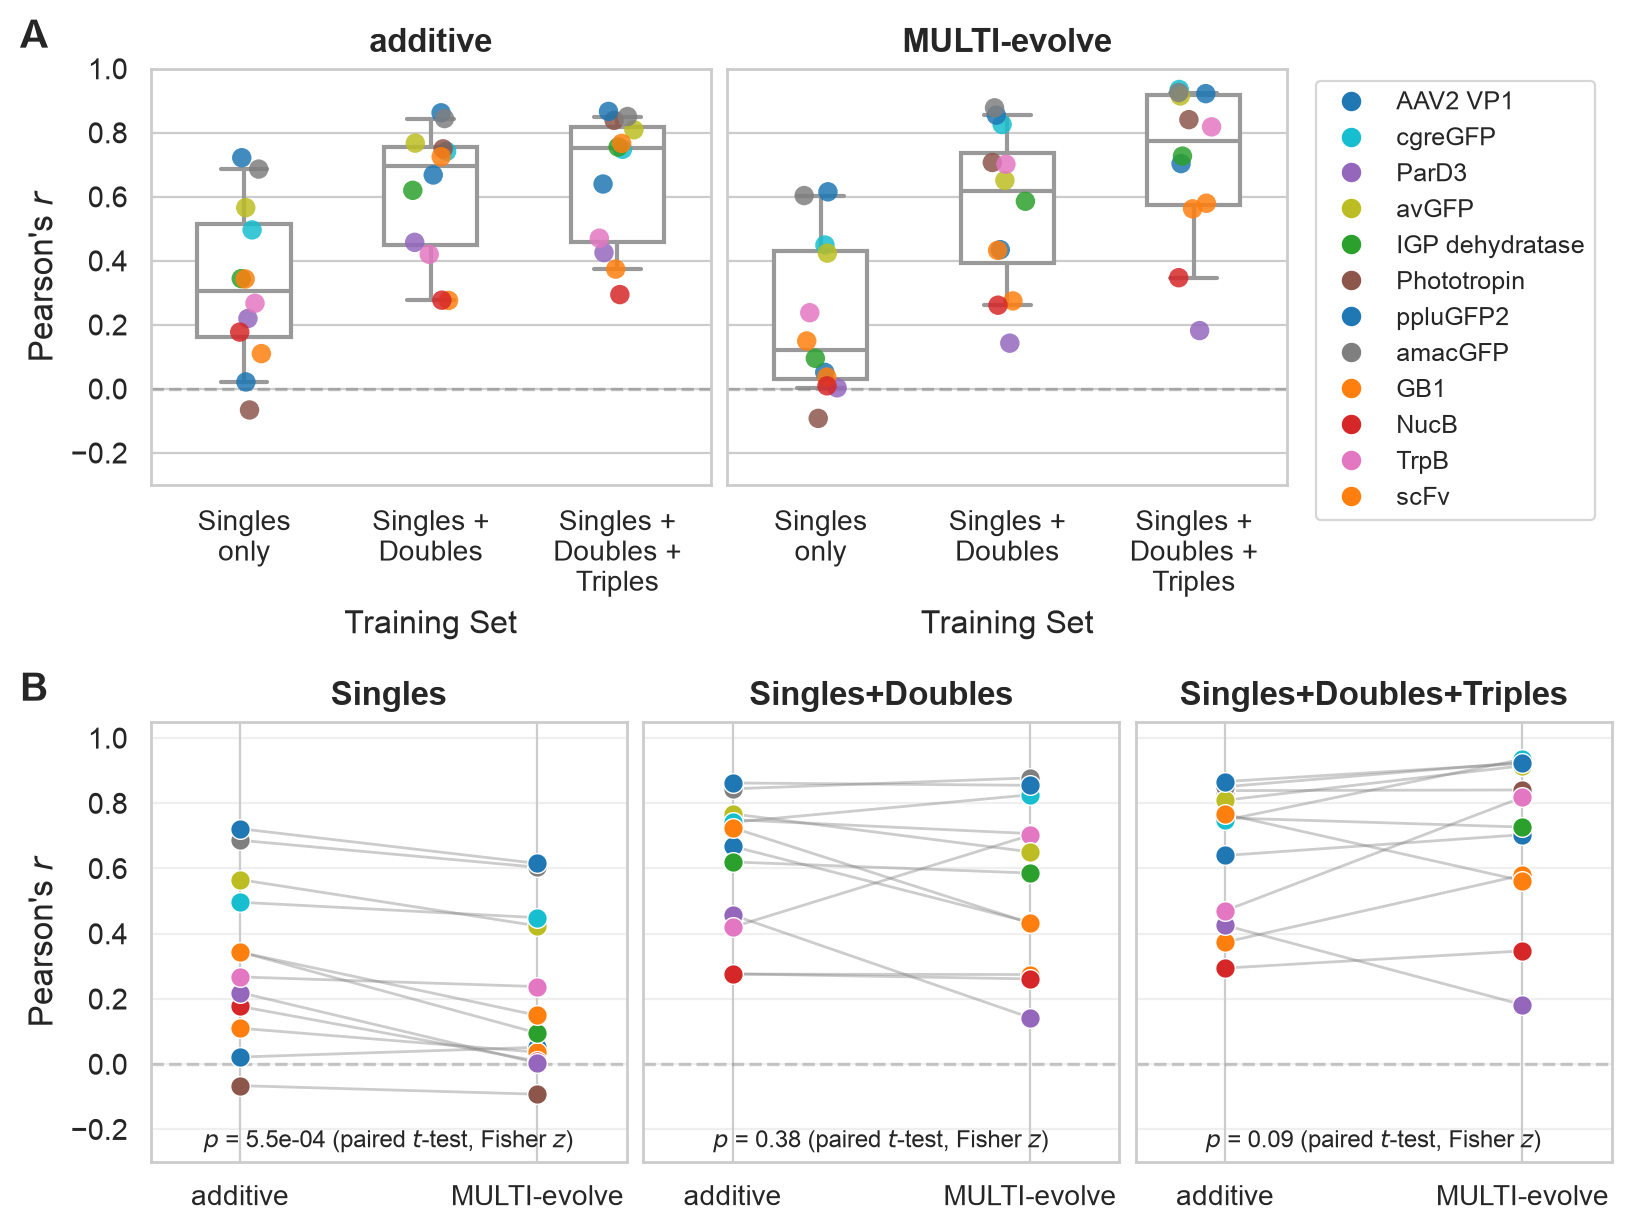

── Paired t-test on Fisher z = arctanh(r) ──
Singles: n=12, t=4.807, p=0.0005
Singles+Doubles: n=12, t=0.914, p=0.3802
Singles+Doubles+Triples: n=12, t=-1.878, p=0.0872


In [37]:
# ── Combined figure: (A) box plots additive vs MULTI-evolve, (B) paired plots with
#    paired t-test on Fisher z = arctanh(r) ──
from scipy.stats import ttest_rel
from matplotlib.lines import Line2D

def fisher_z(r):
    r = np.asarray(r, dtype=float)
    if np.any(~np.isfinite(r)) or np.any(np.abs(r) >= 1):
        raise ValueError(f'Fisher z undefined for r values: {r[~np.isfinite(r) | (np.abs(r) >= 1)]}')
    return np.arctanh(r)

def format_p(p):
    if p < 0.001:
        return f'{p:.1e}'
    if p < 0.01:
        return f'{p:.3f}'
    return f'{p:.2f}'

np.random.seed(0)  # reproducible strip-plot jitter

fig = plt.figure(figsize=(8, 6), layout='constrained')
subfig_a, subfig_b = fig.subfigures(2, 1, height_ratios=[1.15, 1], hspace=0.04)

# ── Panel A: box + strip plots ──
axes_a = subfig_a.subplots(1, 3, width_ratios=[1, 1, 0.55])
axes_a[1].sharey(axes_a[0])
for ax, (data, title) in zip(axes_a[:2], [(overall, 'additive'), (me_onehot, 'MULTI-evolve')]):
    sns.boxplot(data=data, x='training', y='pearson_r', order=order,
                color='white', width=0.5, linewidth=1.5, fliersize=0,
                whis=(5, 95), ax=ax, zorder=2)
    sns.stripplot(data=data, x='training', y='pearson_r', order=order,
                  hue='dataset', palette=dataset_palette, legend=False,
                  size=7, jitter=True, dodge=False, alpha=0.85, ax=ax, zorder=3)
    ax.set_xticks(range(len(order)))
    ax.set_xticklabels(xticklabels, fontsize=10)
    ax.set_xlabel('Training Set')
    ax.set_ylim(-0.3, 1.)
    ax.axhline(0, color='gray', linestyle='--', alpha=0.5)
    ax.set_title(title, fontsize=12, fontweight='bold')
axes_a[0].set_ylabel("Pearson's $r$", fontsize=12)
axes_a[1].set_ylabel('')
axes_a[1].tick_params(labelleft=False)

# Legend in dataset order (same order as the benchmarking table)
handles = [Line2D([0], [0], marker='o', color='w', markerfacecolor=dataset_palette[d],
                  markersize=8, label=d) for d in overall['dataset'].unique()]
axes_a[2].axis('off')
axes_a[2].legend(handles=handles, loc='upper left', fontsize=9, frameon=True)

# ── Panel B: paired dot plots, Fisher-z paired t-test ──
axes_b = subfig_b.subplots(1, 3, sharey=True)
fisher_stats = []
for ax, config in zip(axes_b, order):
    sub = comparison[comparison['training'] == config].sort_values('dataset')
    ridge_vals = sub['additive_r'].values
    me_vals = sub['me_r'].values

    for rv, mv in zip(ridge_vals, me_vals):
        ax.plot([0, 1], [rv, mv], color='gray', alpha=0.4, linewidth=1, zorder=1)
    for rv, mv, ds in zip(ridge_vals, me_vals, sub['dataset'].values):
        ax.scatter([0, 1], [rv, mv], color=dataset_palette[ds], s=50, zorder=3,
                   edgecolors='white', linewidth=0.5)

    stat, pval = ttest_rel(fisher_z(ridge_vals), fisher_z(me_vals))
    fisher_stats.append((config, len(sub), stat, pval))
    ax.text(0.5, 0.02, f'$p$ = {format_p(pval)} (paired $t$-test, Fisher $z$)',
            ha='center', va='bottom', fontsize=8.5, transform=ax.transAxes)

    ax.set_xticks([0, 1])
    ax.set_xticklabels(['additive', 'MULTI-evolve'], fontsize=10)
    ax.set_xlim(-0.3, 1.3)
    ax.set_ylim(-0.3, 1.05)
    ax.set_title(config, fontsize=12, fontweight='bold')
    ax.axhline(0, color='gray', linestyle='--', alpha=0.4)
    ax.grid(True, axis='y', alpha=0.3)
axes_b[0].set_ylabel("Pearson's $r$", fontsize=12)

subfig_a.text(0.0, 1.0, 'A', fontsize=14, fontweight='bold', va='top')
subfig_b.text(0.0, 1.0, 'B', fontsize=14, fontweight='bold', va='top')

plt.savefig(FIGURES_DIR / 'fig2e_comparison_fisherz.pdf', bbox_inches='tight')
plt.show()

print('── Paired t-test on Fisher z = arctanh(r) ──')
for config, n, stat, pval in fisher_stats:
    print(f'{config}: n={n}, t={stat:.3f}, p={pval:.4f}')

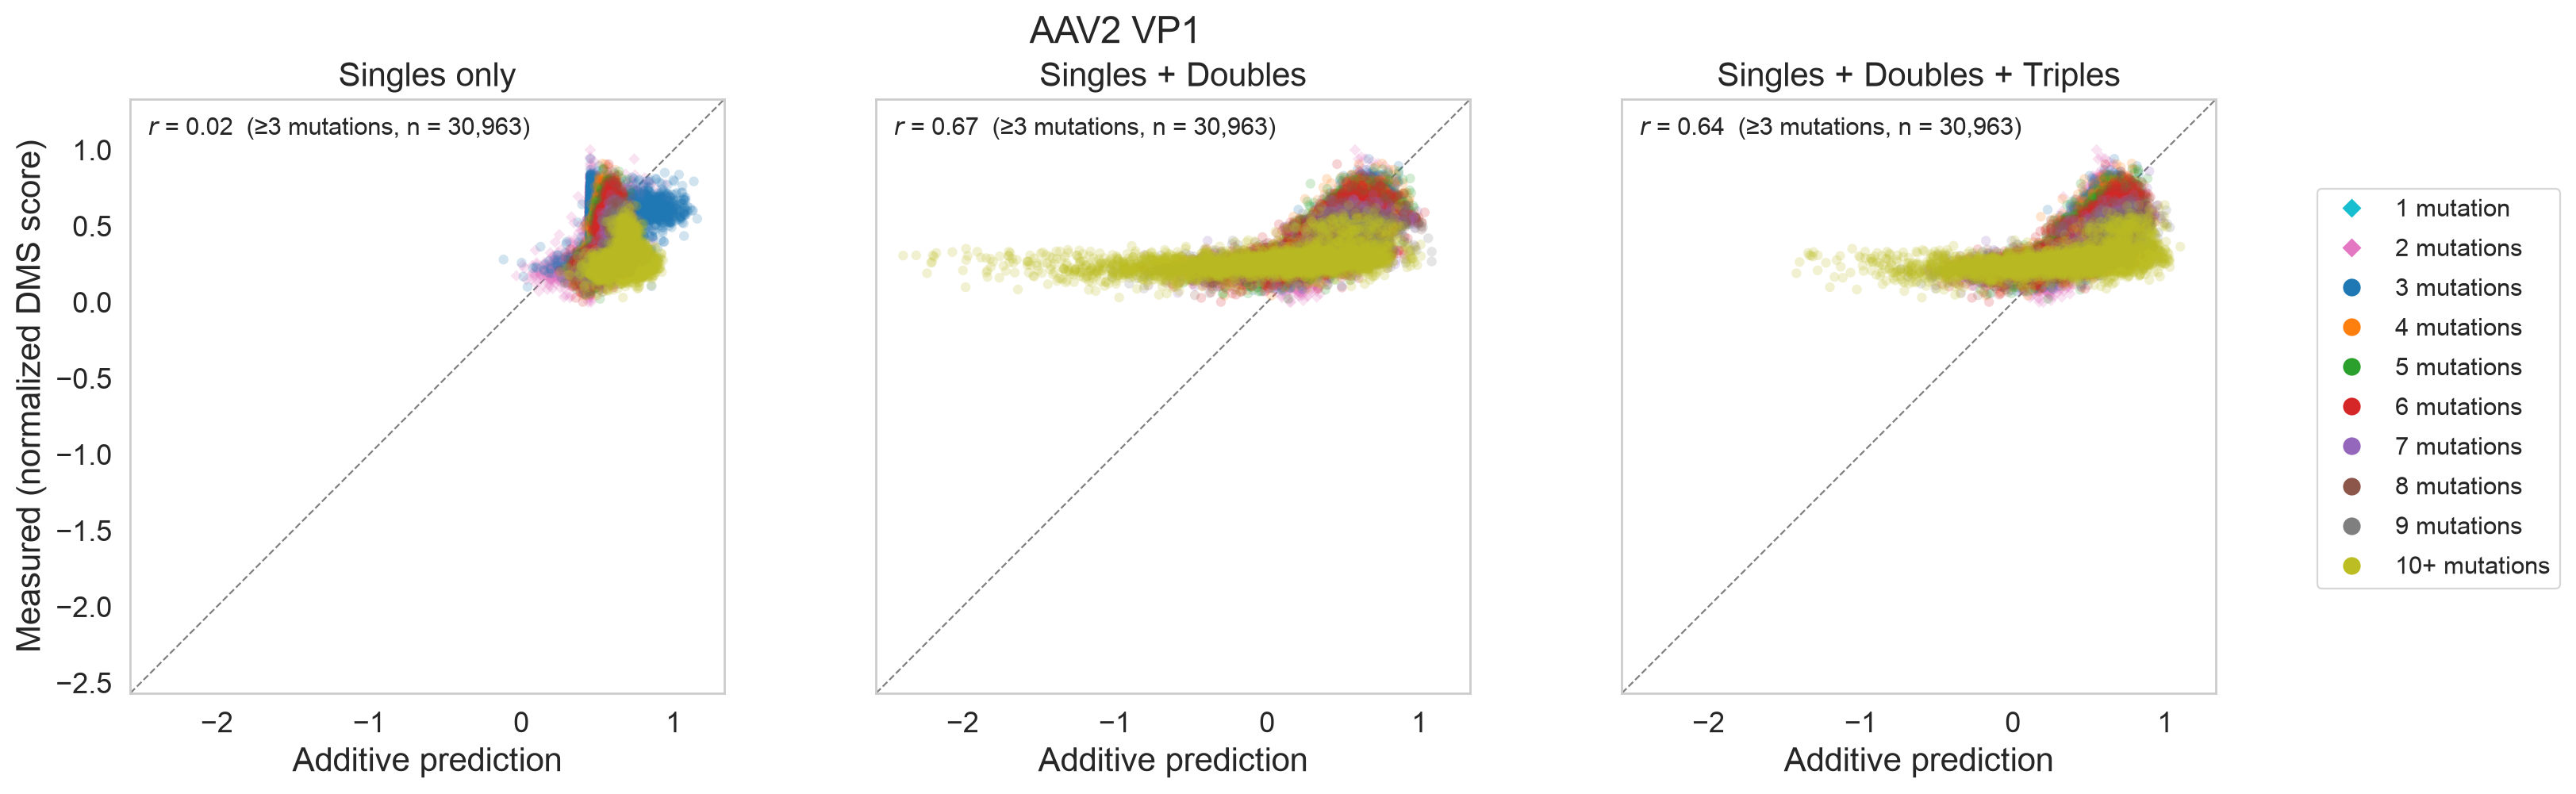

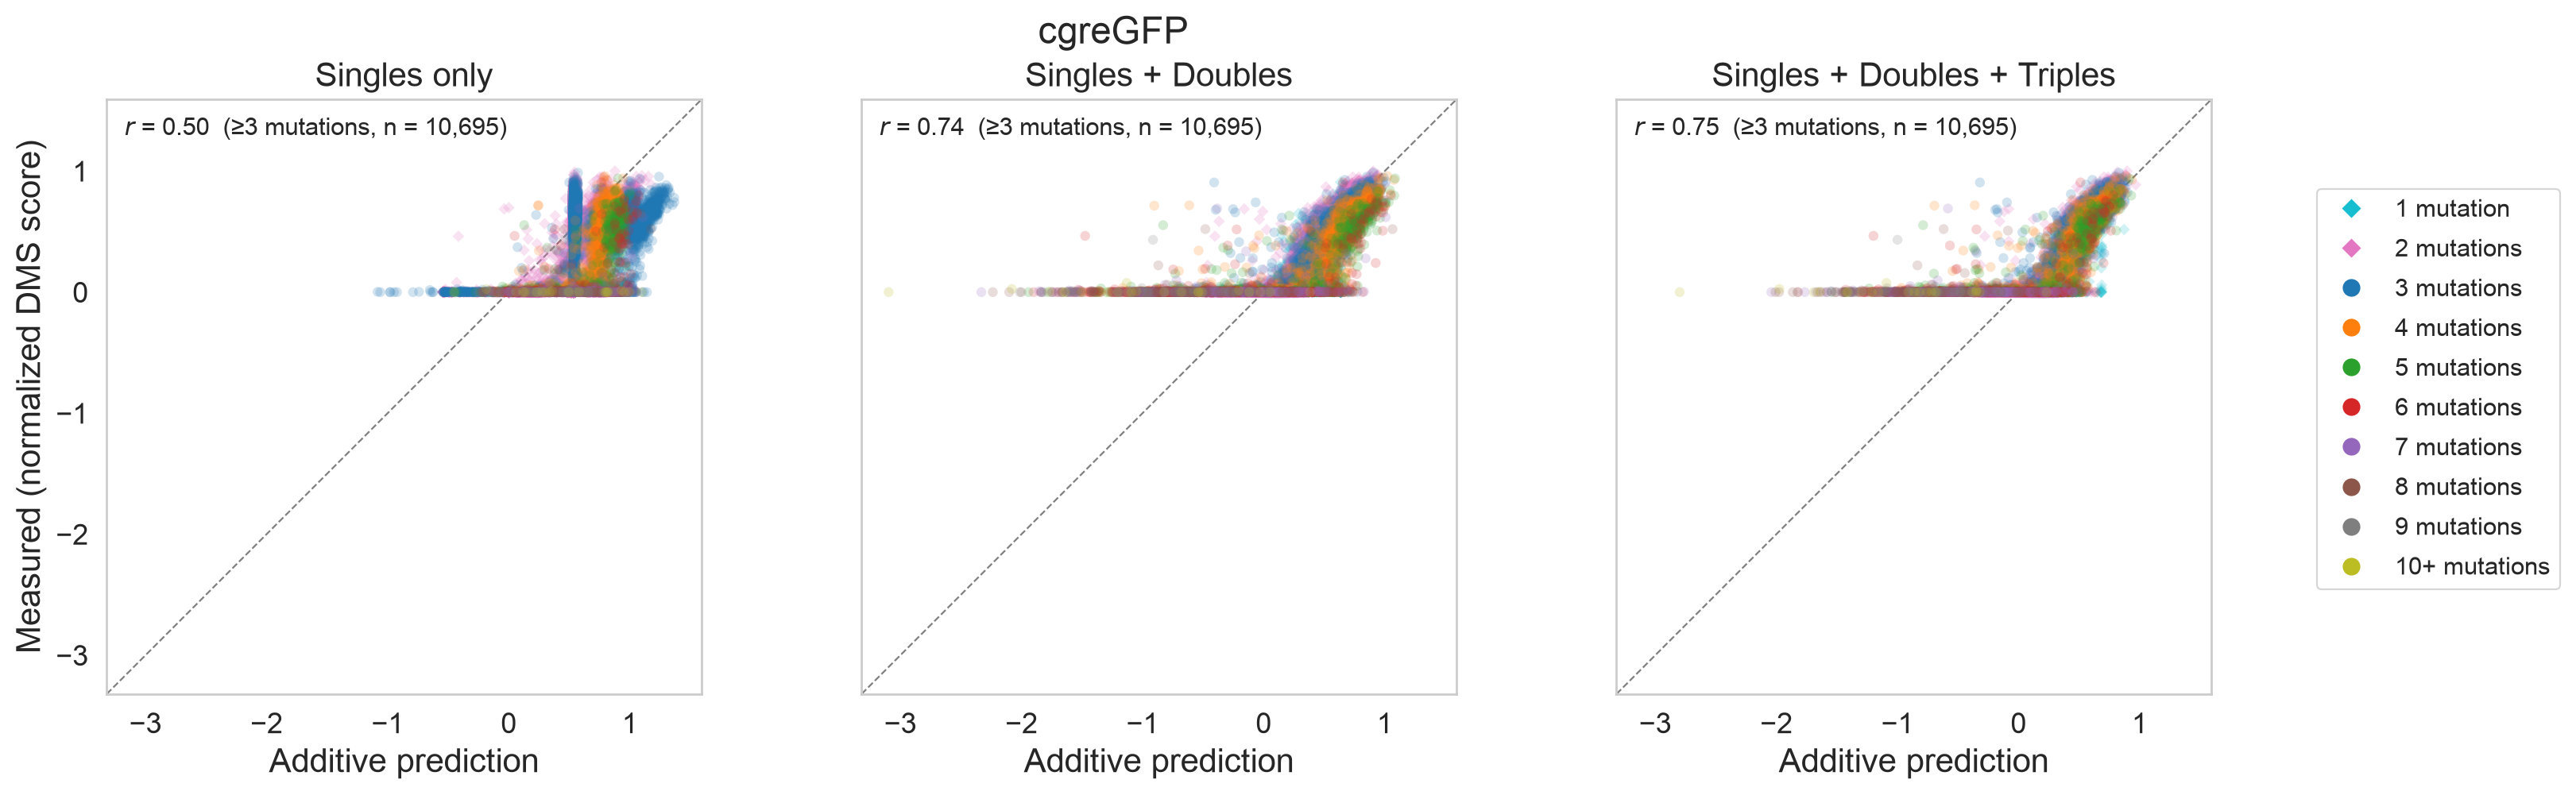

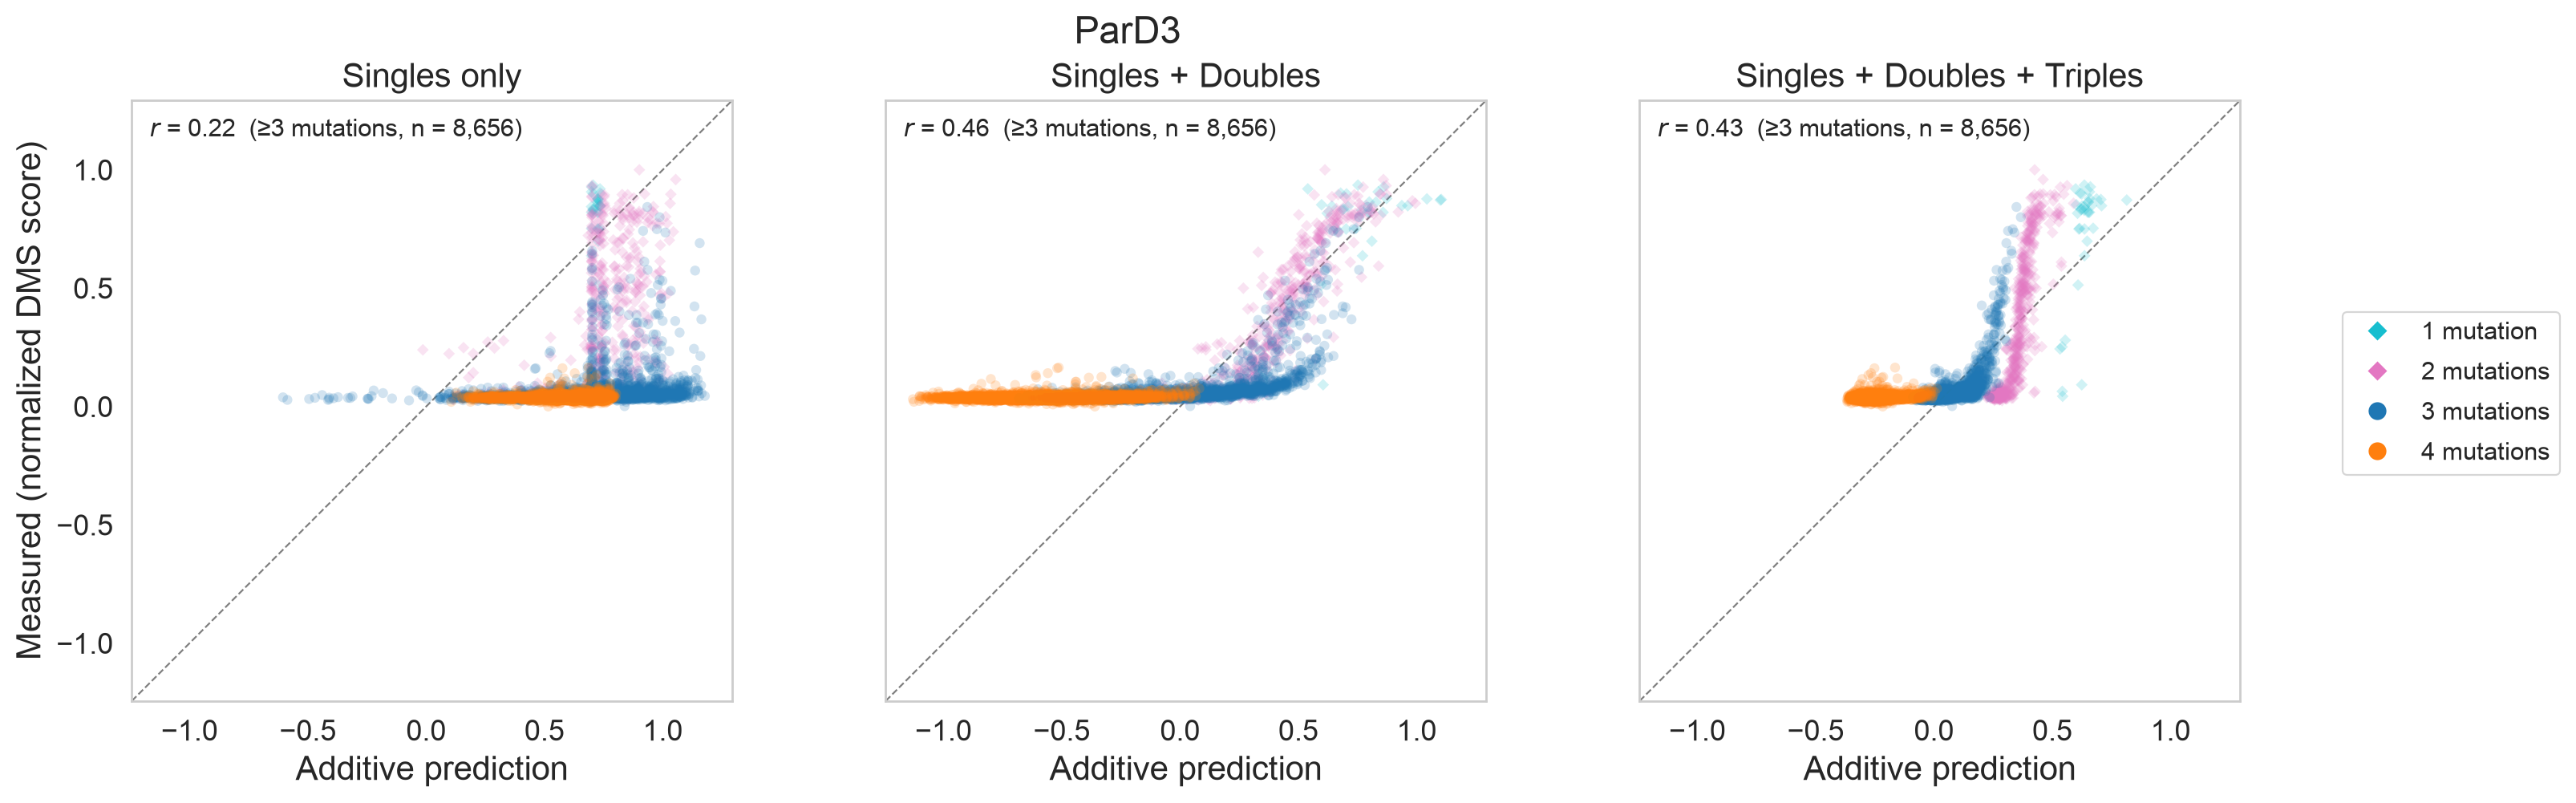

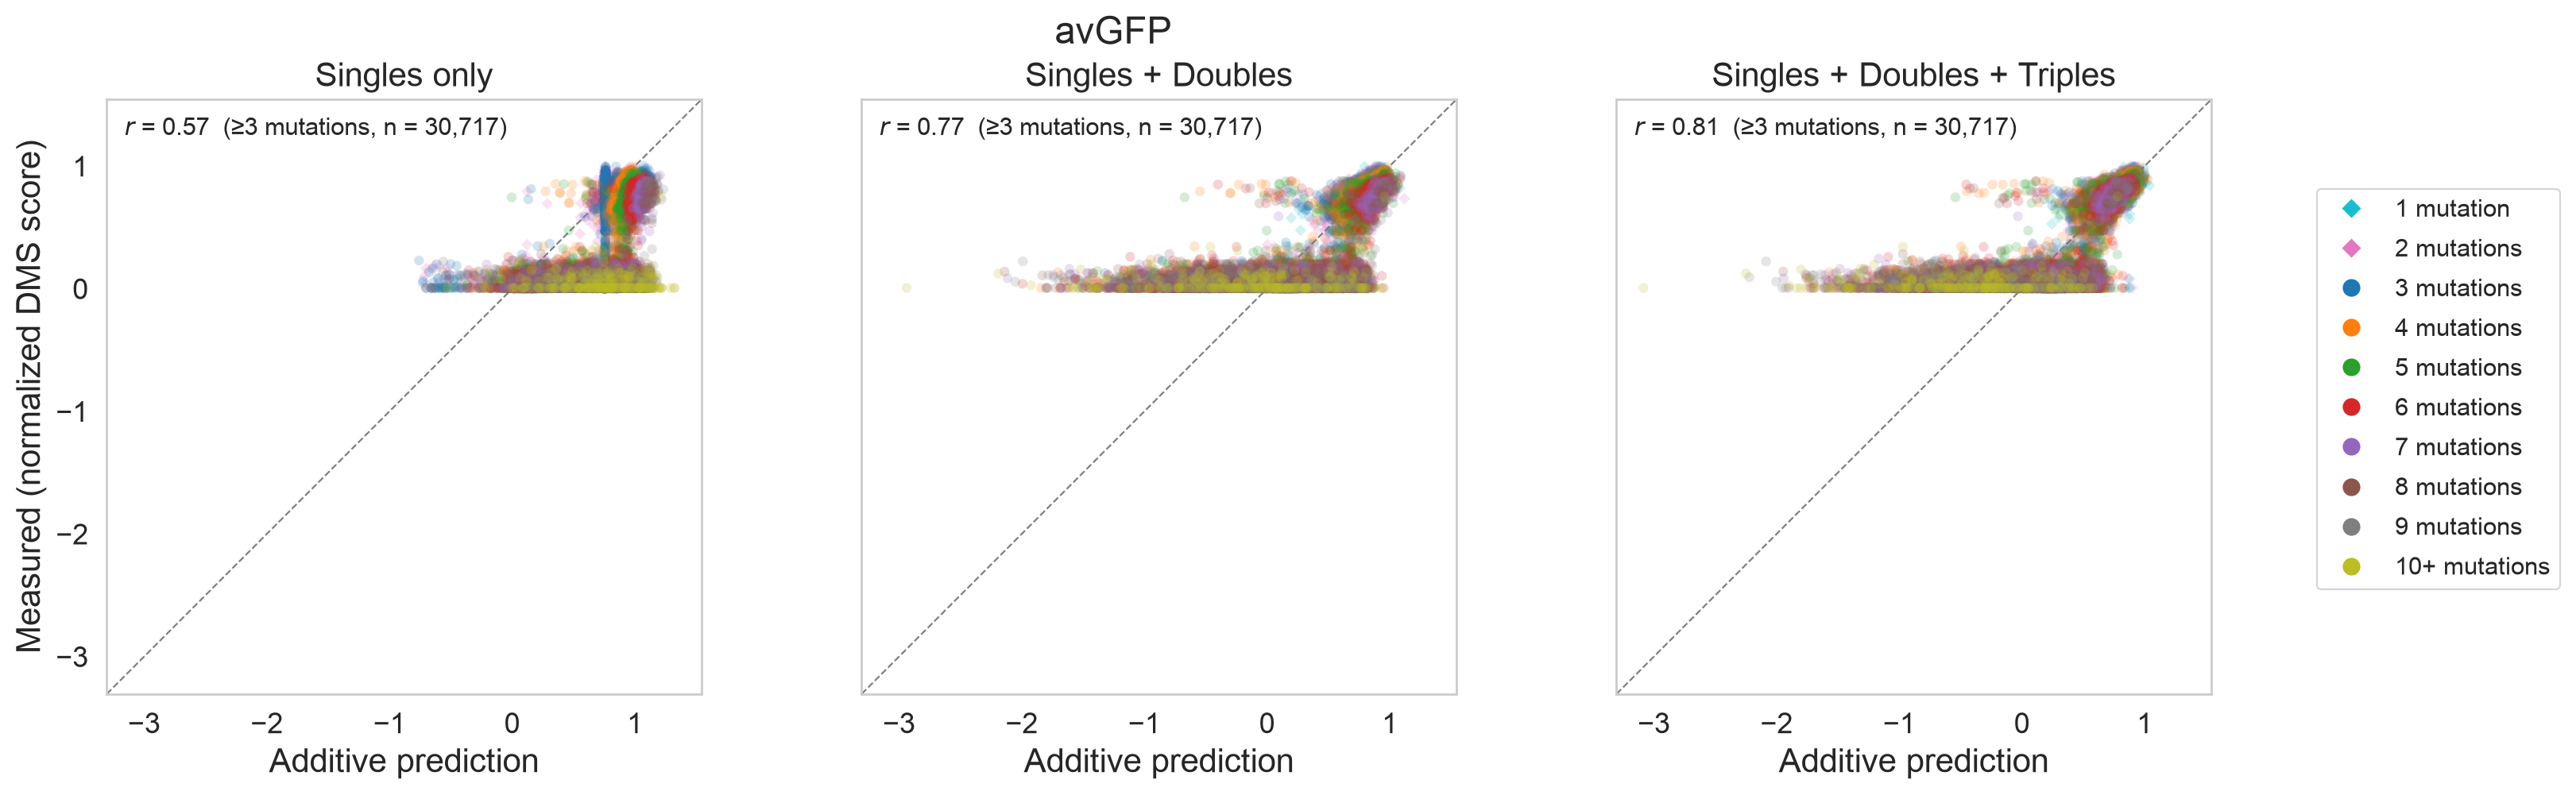

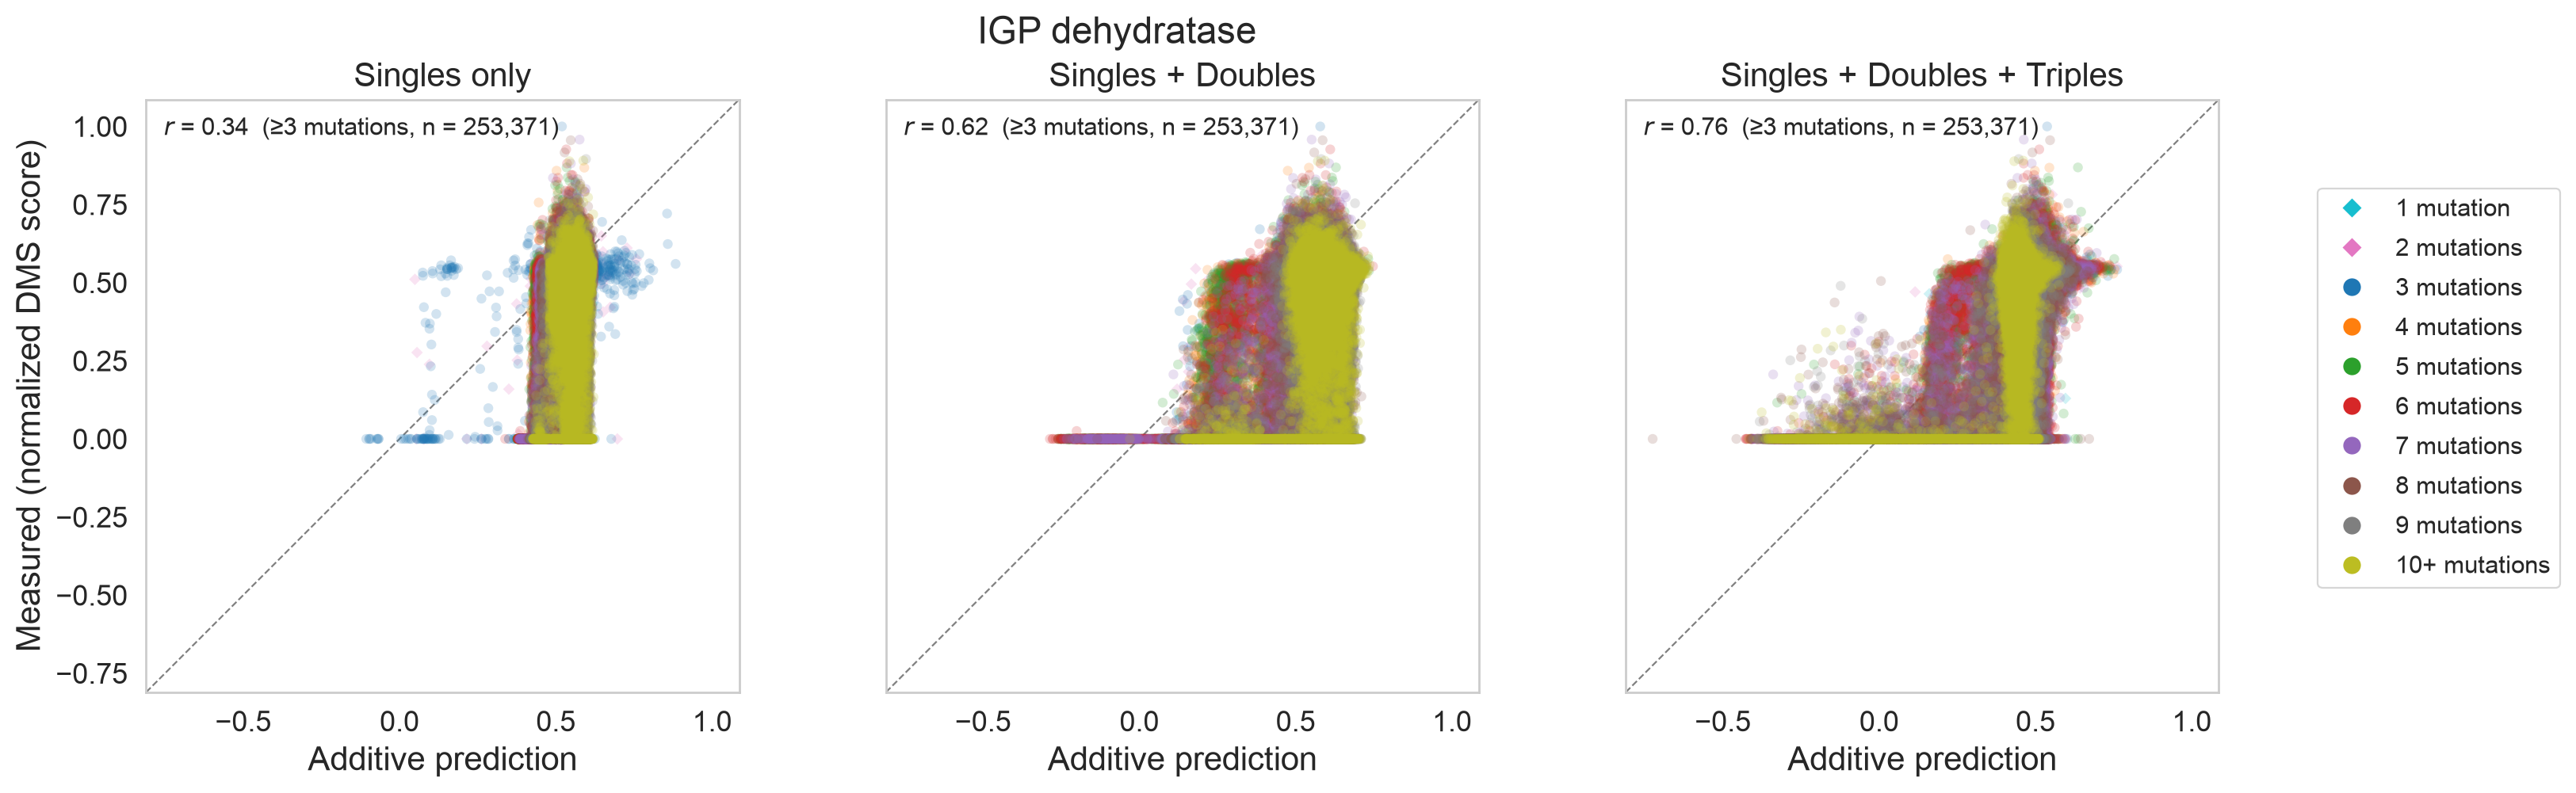

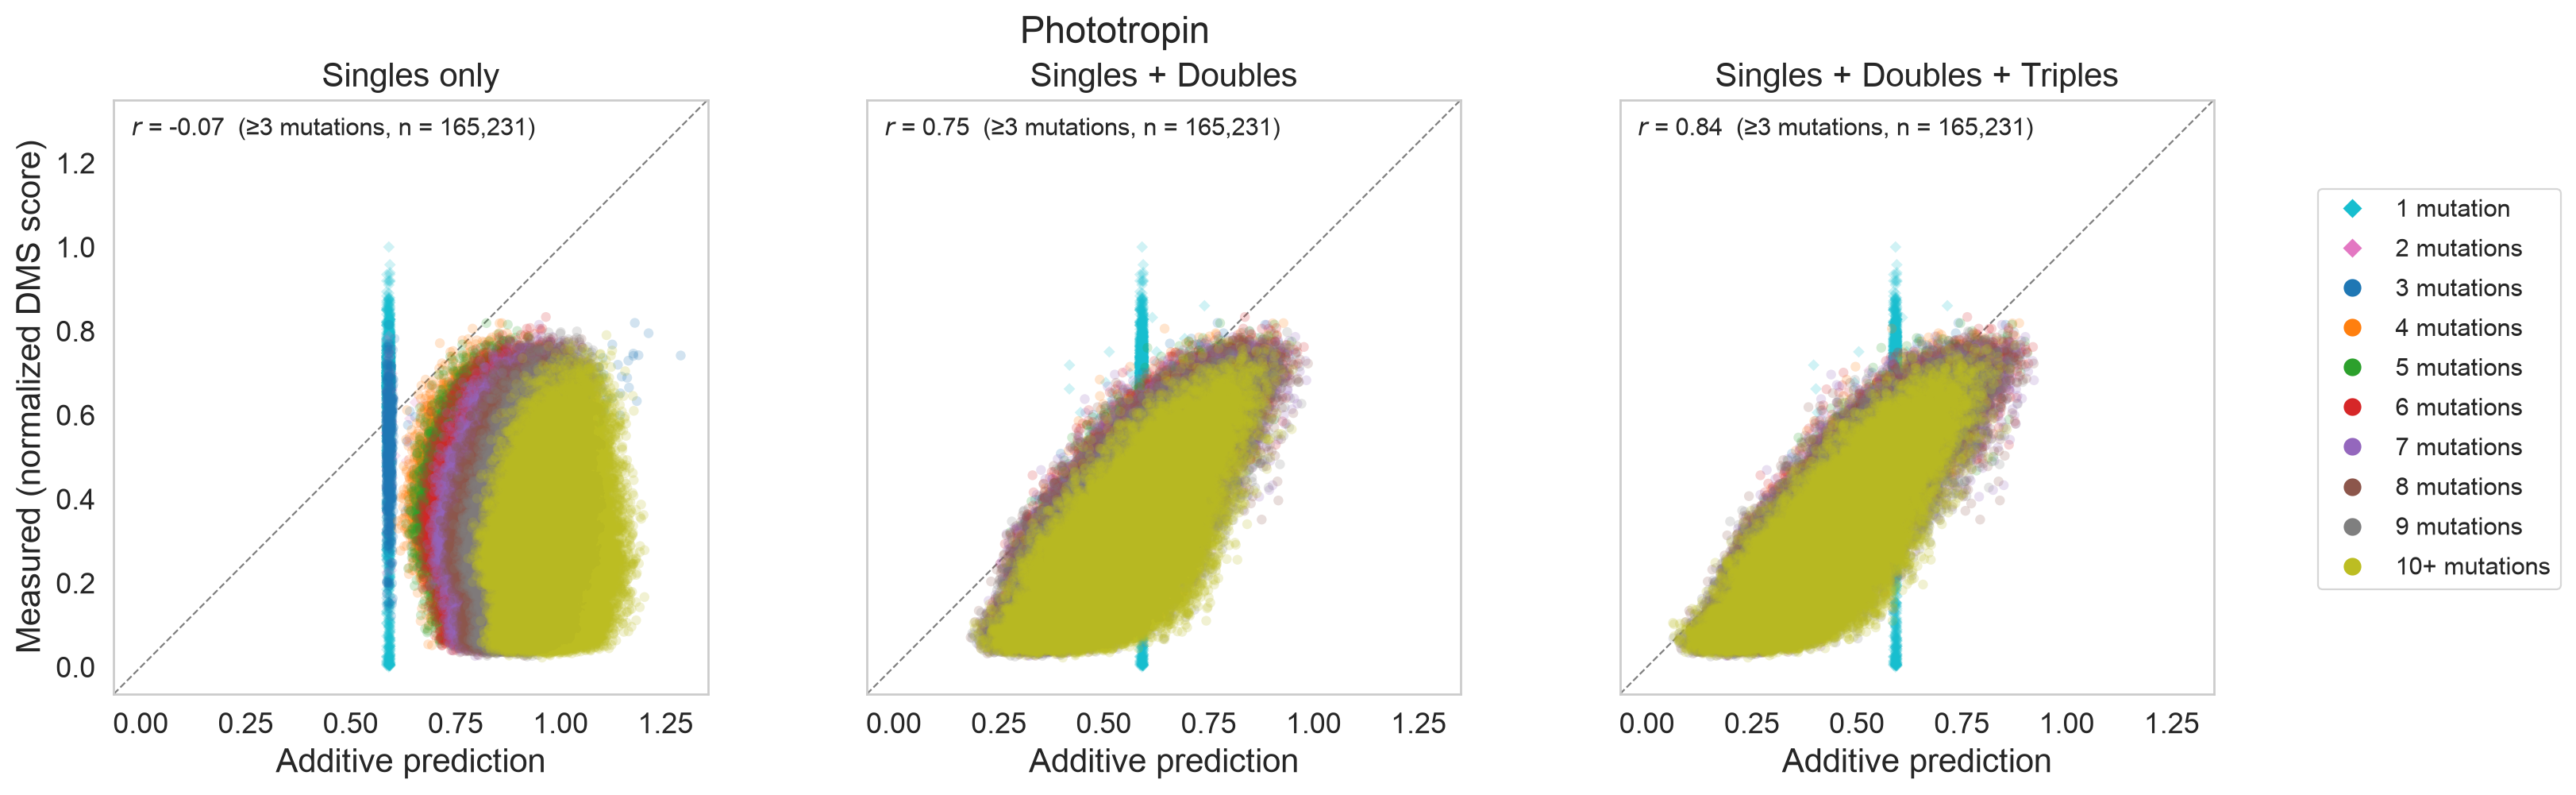

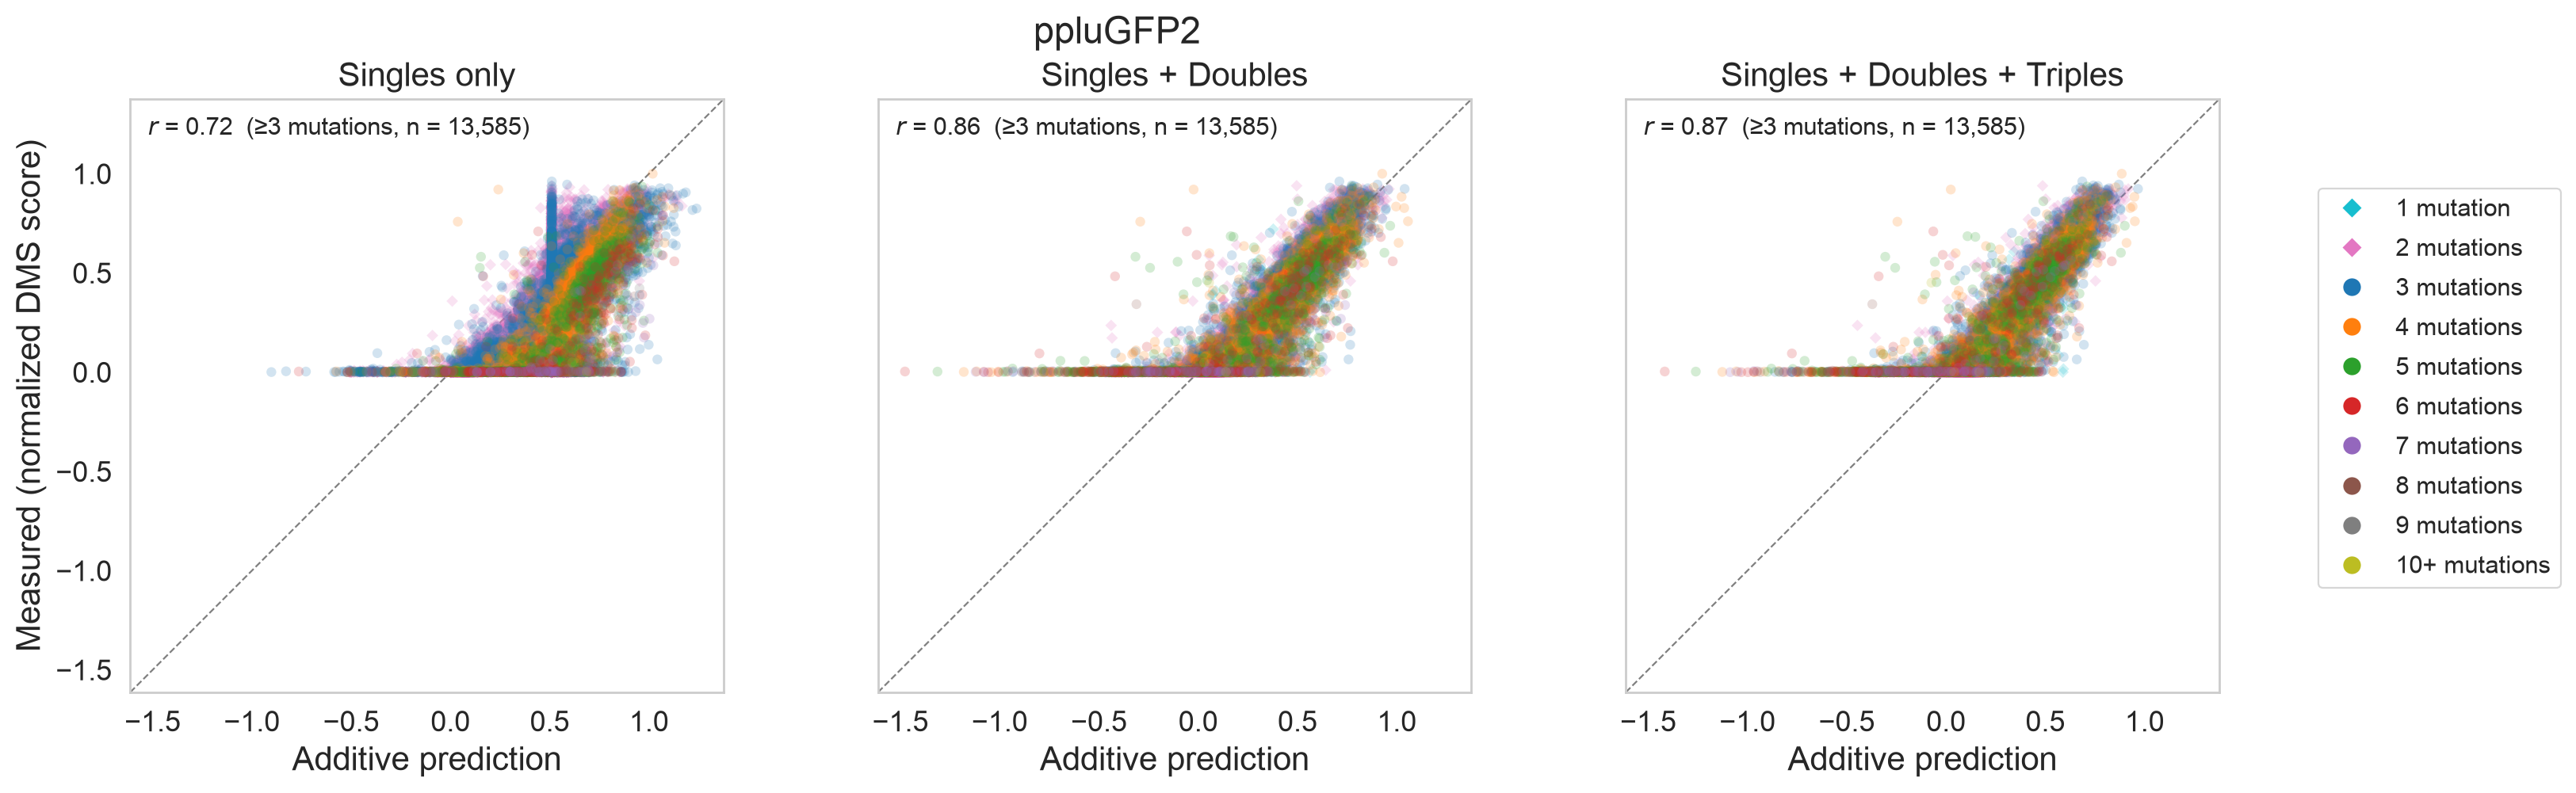

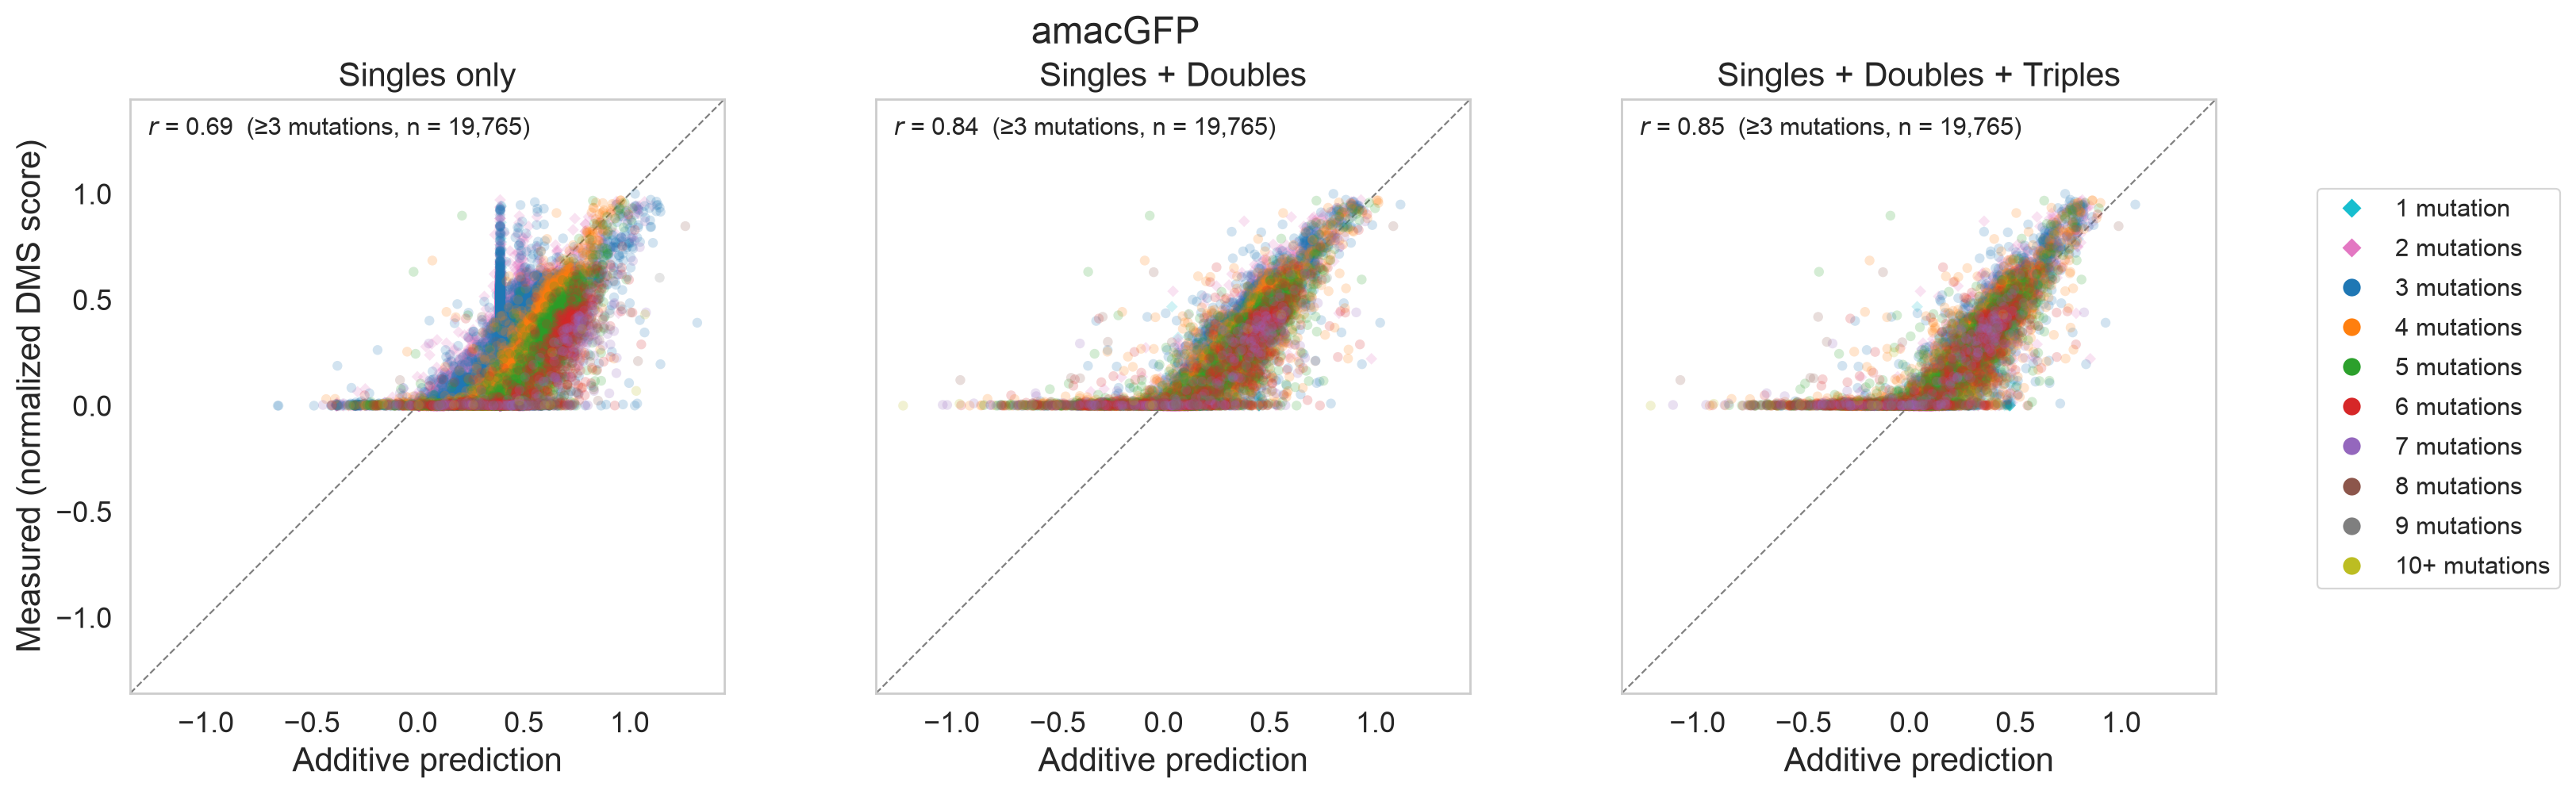

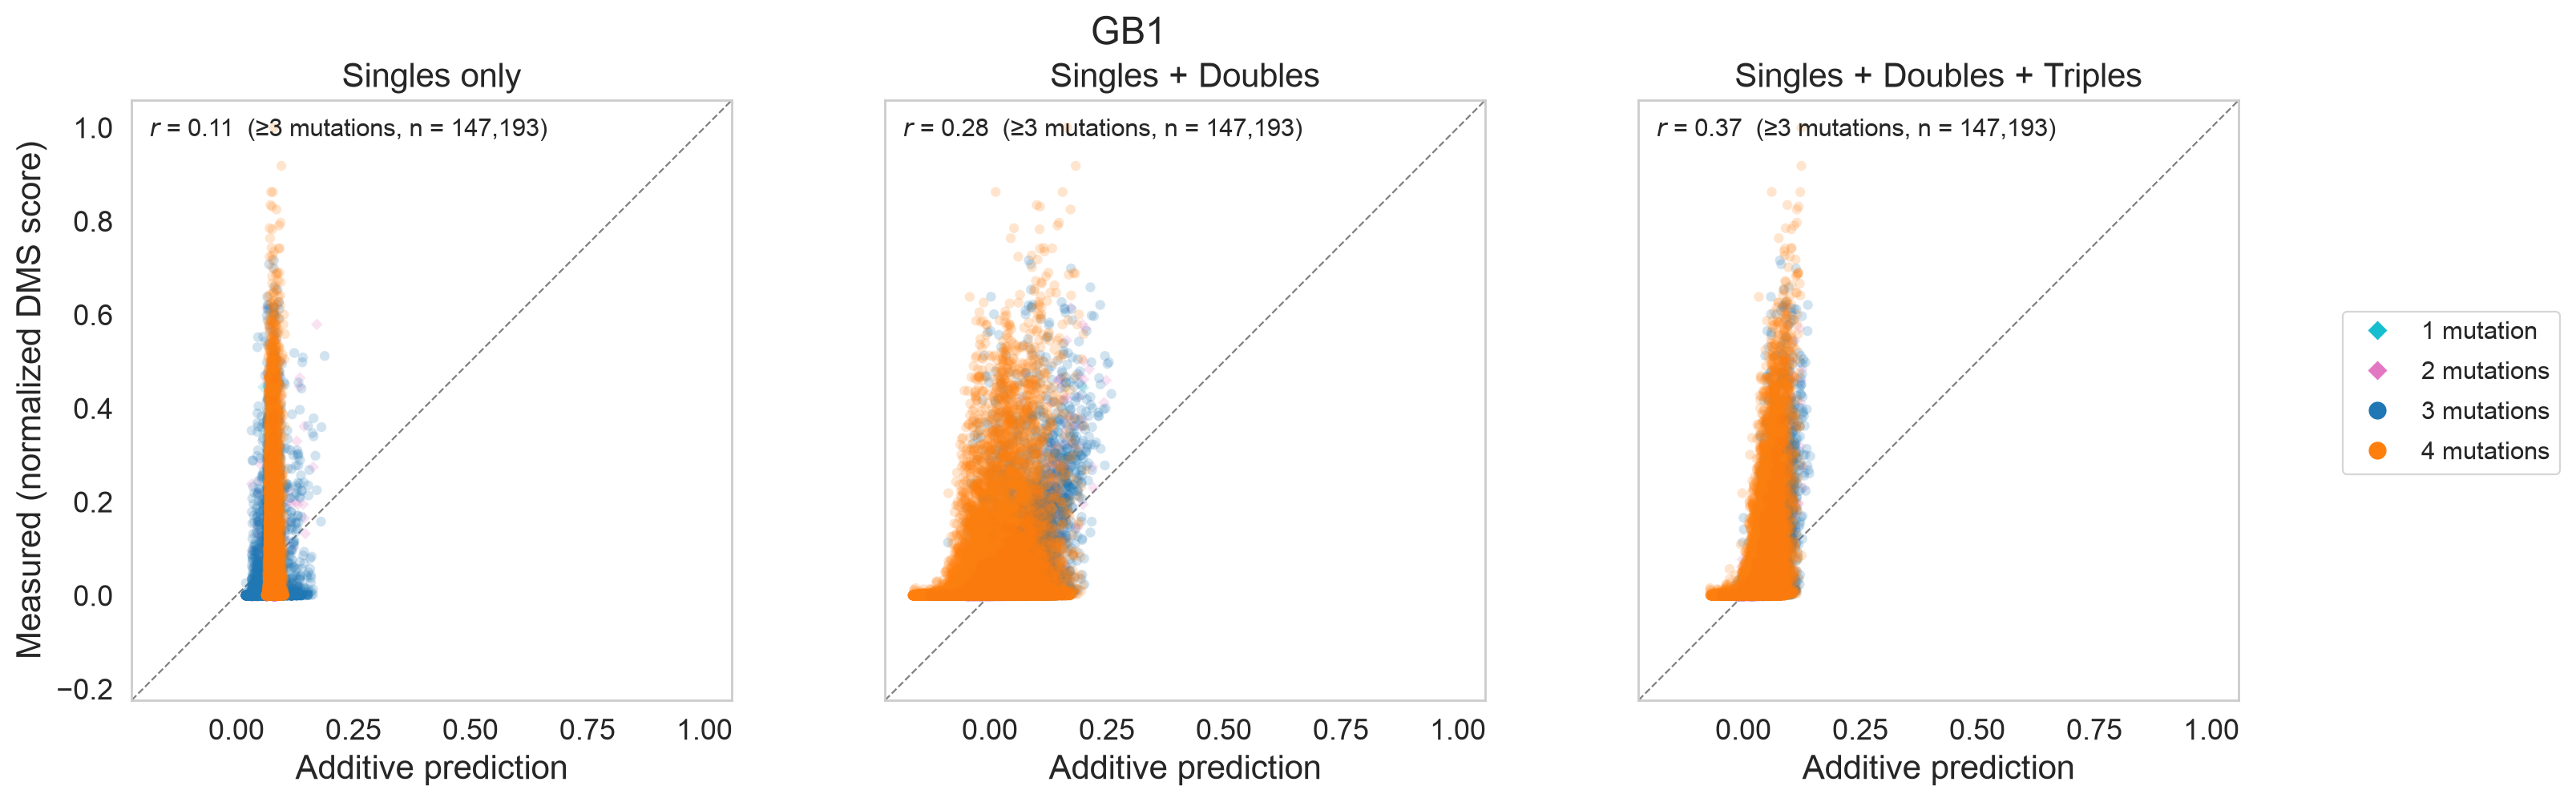

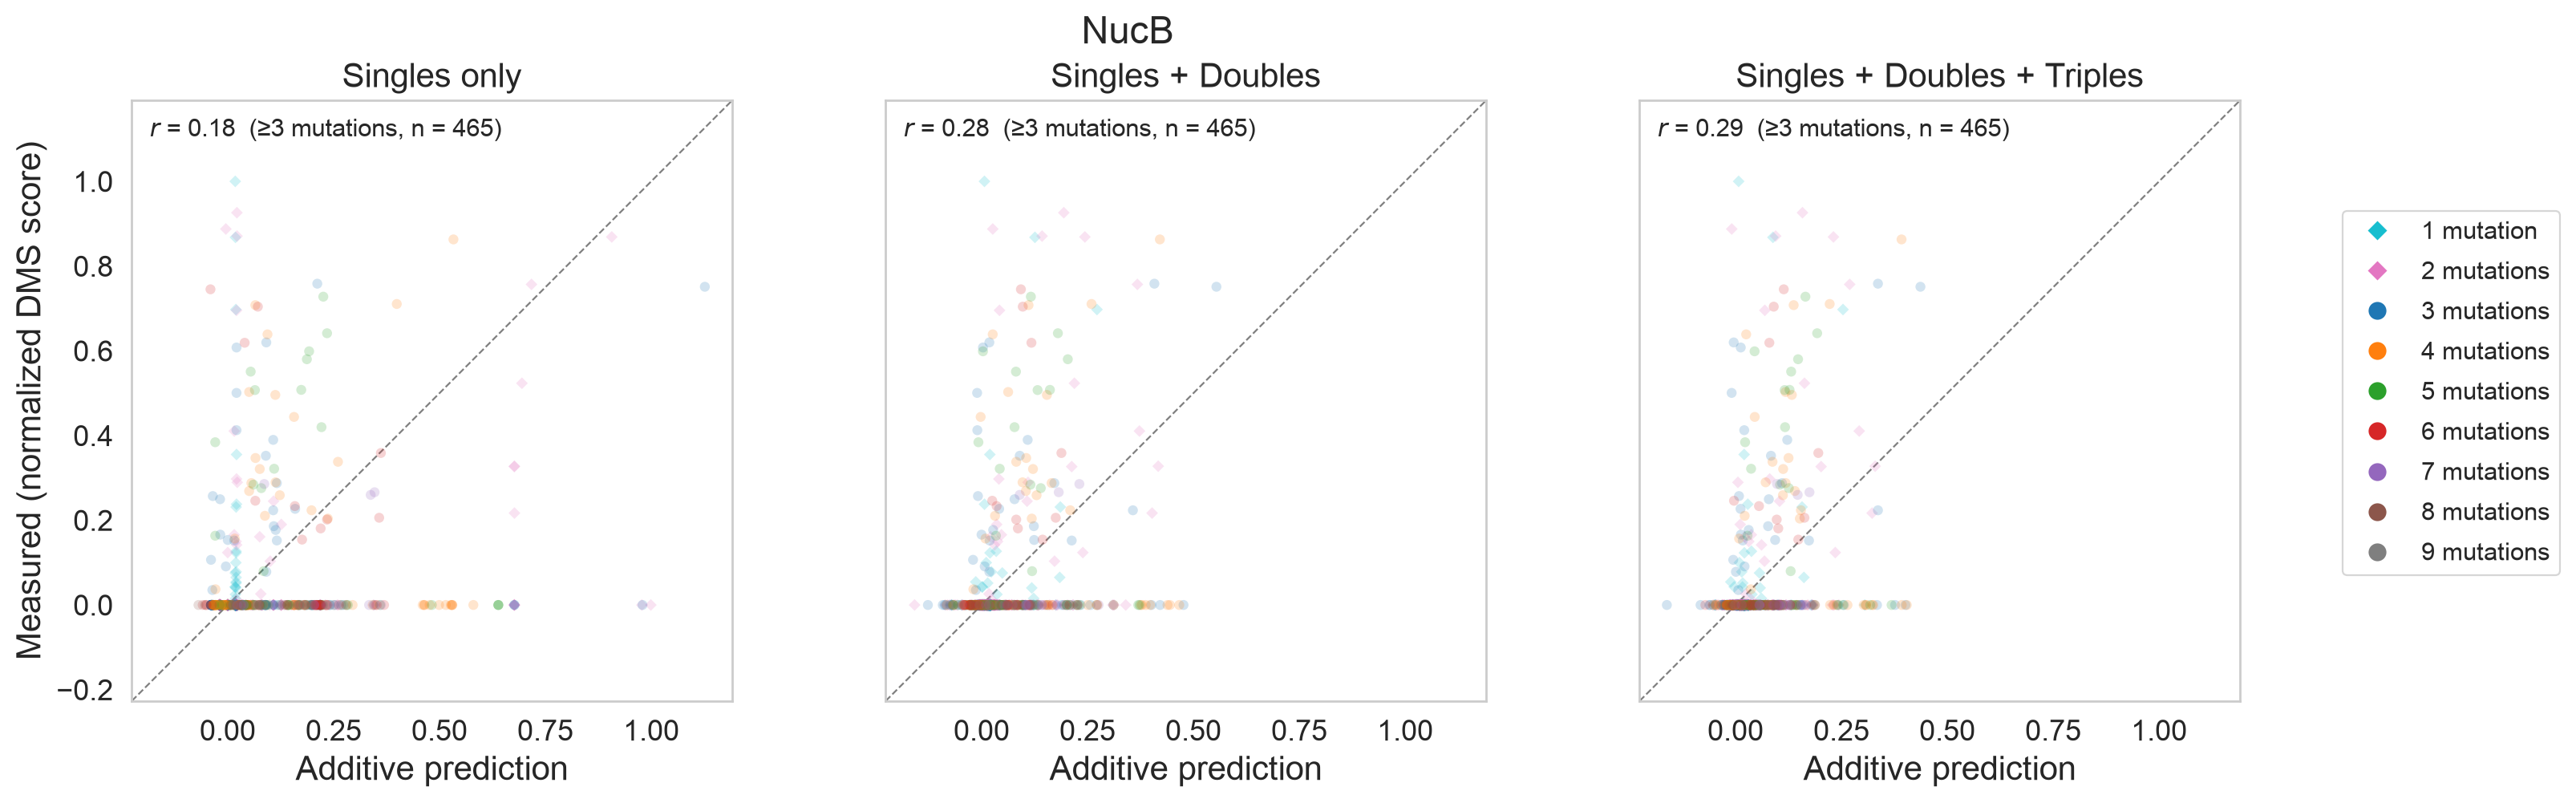

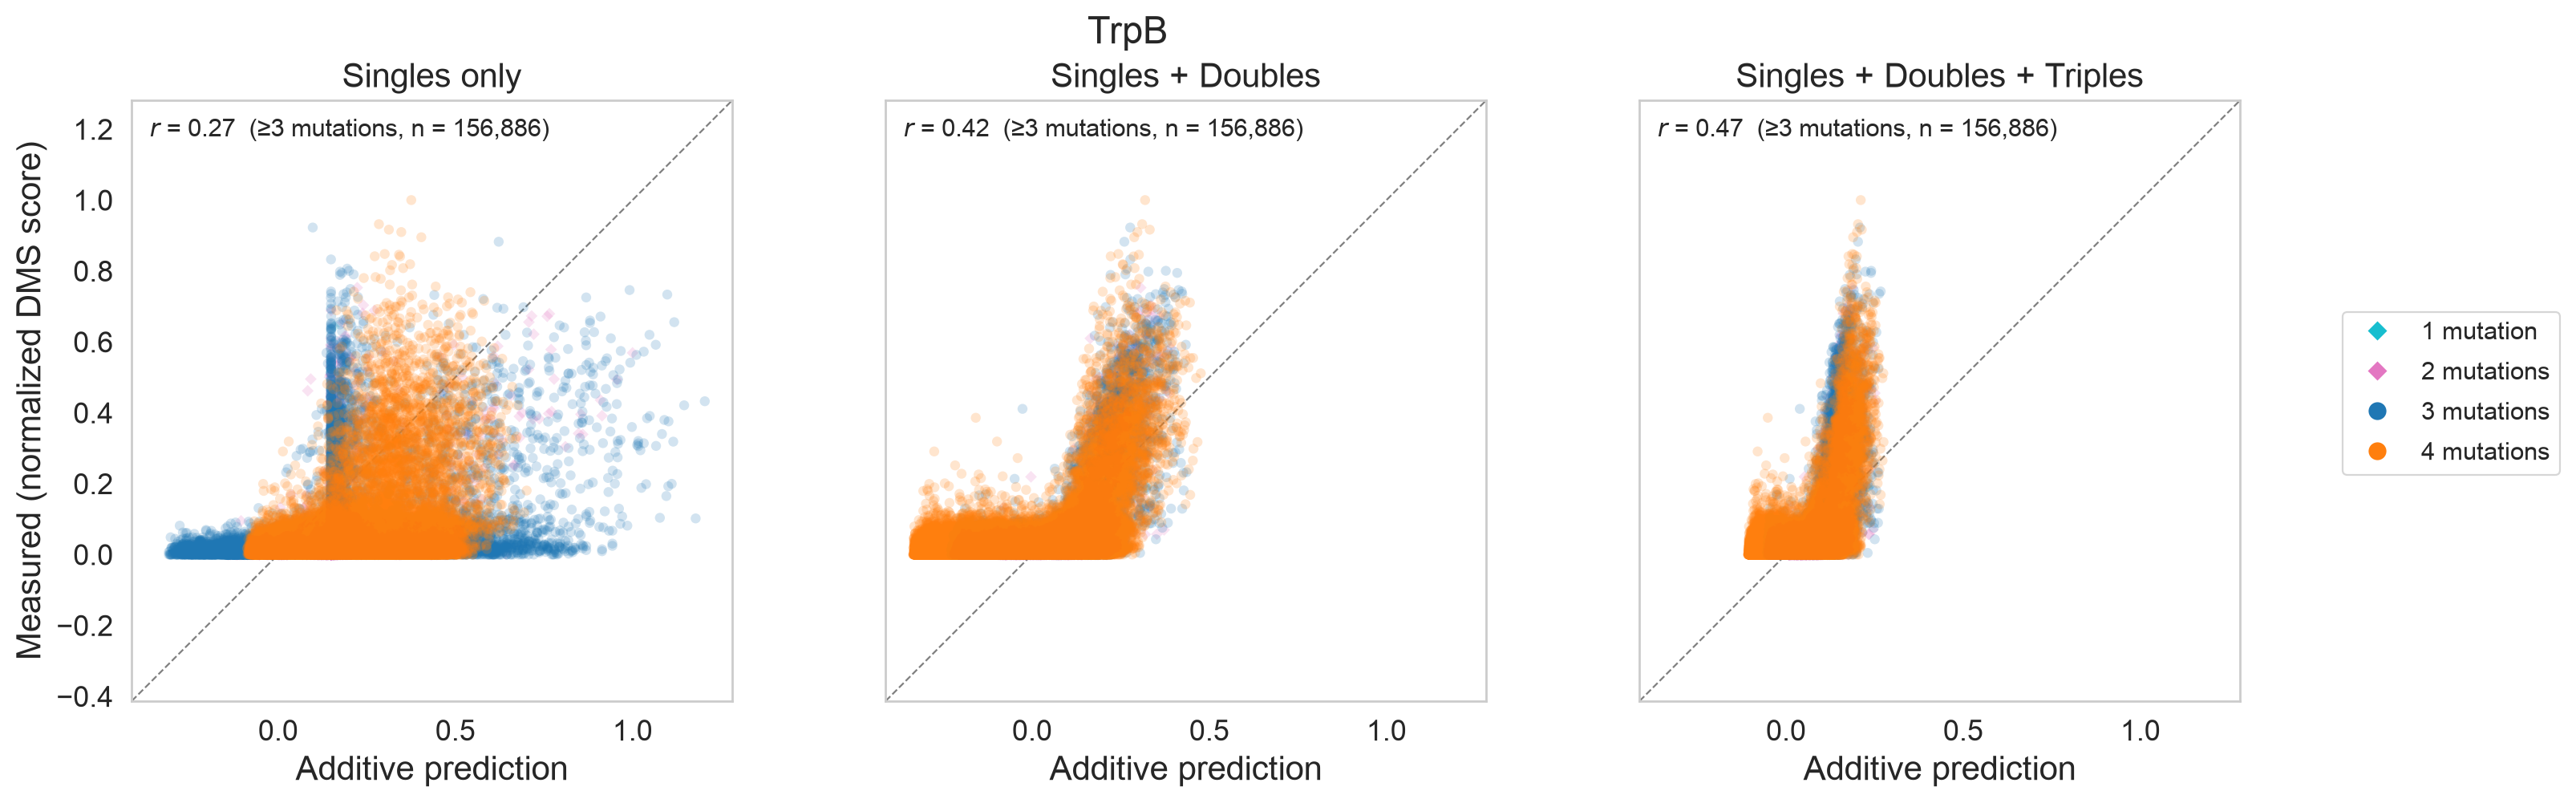

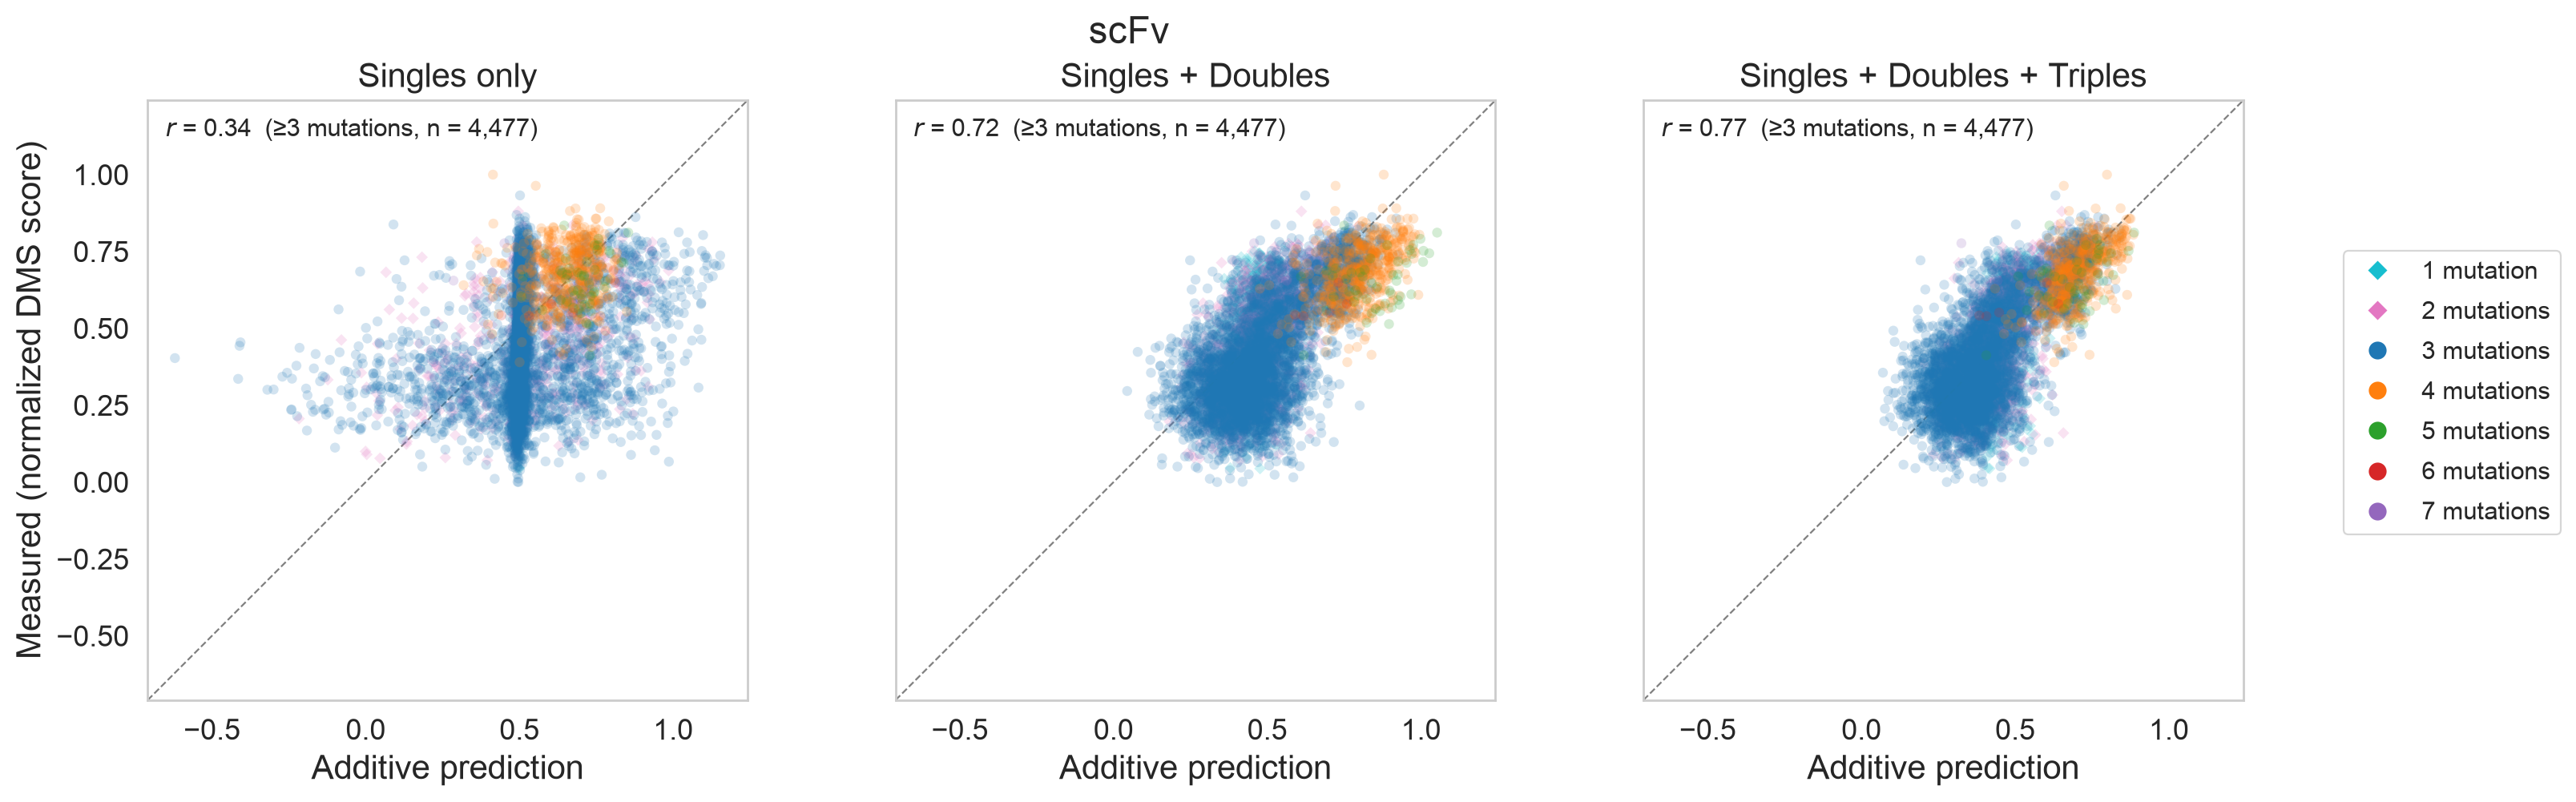

In [38]:
# using the predictions saved locally, for each of the 12 datasets, make a scatterplot with predicted vs experimental,
# like multievolve-baselines/figures/apex_predictions_vs_measured.pdf but without black outline on the markers and with alpha=0.2
#
# One figure per dataset, one panel per training configuration (additive model only: MULTI-evolve
# per-variant predictions are not available). Points are colored by number of mutations, using the
# same colors as the APEX / dCasRx / HuABC2 notebooks; 10+ mutations share one color.
#   diamonds: 1-2 mutations (held-out CV predictions; not part of the reported r)
#   circles : >=3 mutations (the variants the reported Pearson r is computed on)
# Needs only the imports cell and the files written by the 'save raw predictions' cell.
from matplotlib.lines import Line2D

PRED_DIR = Path('../output/proteingym')
SCATTER_DIR = Path('../figures')
TRAINING_ORDER = ['Singles', 'Singles+Doubles', 'Singles+Doubles+Triples']
TRAINING_TITLES = ['Singles only', 'Singles + Doubles', 'Singles + Doubles + Triples']

N_COLORS = {1: 'C9', 2: 'C6', 3: 'C0', 4: 'C1', 5: 'C2', 6: 'C3', 7: 'C4', 8: 'C5', 9: 'C7'}
COLOR_10PLUS = 'C8'
LOAD_BINS = [(n, n, N_COLORS[n], f'{n} mutation' + ('s' if n > 1 else '')) for n in range(1, 10)]
LOAD_BINS.append((10, np.inf, COLOR_10PLUS, '10+ mutations'))

preds = pd.read_csv(PRED_DIR / 'additive_ridge_predictions.csv')
saved_results = pd.read_csv(PRED_DIR / 'additive_ridge_results.csv')
saved_overall = saved_results[saved_results['test_mut_load'].isna()].set_index(['dataset', 'training'])

for ds in preds['dataset'].unique():
    d = preds[preds['dataset'] == ds]

    # common limits so all panels share the same x and y range
    lo = min(d['y_true'].min(), d['y_pred'].min())
    hi = max(d['y_true'].max(), d['y_pred'].max())
    pad = 0.05 * (hi - lo)
    lims = [lo - pad, hi + pad]

    fig, axes = plt.subplots(1, 3, figsize=(15, 4.9), sharex=True, sharey=True)
    present_bins = set()
    for ax, config, title in zip(axes, TRAINING_ORDER, TRAINING_TITLES):
        g = d[d['training'] == config]
        for n_lo, n_hi, color, label in LOAD_BINS:   # low loads first, higher loads drawn on top
            b = g[(g['n_mutations'] >= n_lo) & (g['n_mutations'] <= n_hi)]
            if len(b) == 0:
                continue
            present_bins.add(label)
            ax.scatter(b['y_pred'], b['y_true'], s=14 if n_hi <= 2 else 20,
                       marker='D' if n_hi <= 2 else 'o', color=color,
                       edgecolors='none', alpha=0.2, rasterized=True, zorder=3)

        # Pearson r on the evaluated variants (>=3 mutations), checked against the saved results
        ev = g[g['in_eval']]
        r = pearson_r(ev['y_true'].values, ev['y_pred'].values)
        r_saved = saved_overall.loc[(ds, config), 'pearson_r']
        if not np.isclose(r, r_saved, rtol=0, atol=1e-10):
            raise ValueError(f'{ds} / {config}: r from predictions {r:.6f} != saved r {r_saved:.6f}')
        ax.text(0.03, 0.97, f'$r$ = {r:.2f}  (≥3 mutations, n = {len(ev):,})',
                transform=ax.transAxes, ha='left', va='top', fontsize=11)

        ax.plot(lims, lims, color='gray', linestyle='--', linewidth=0.8, zorder=1)
        ax.set_xlim(lims); ax.set_ylim(lims)
        ax.set_aspect('equal', adjustable='box')
        ax.set_title(title, fontsize=15)
        ax.set_xlabel('Additive prediction', fontsize=15)
        ax.tick_params(labelsize=13)
        ax.grid(False)
    axes[0].set_ylabel('Measured (normalized DMS score)', fontsize=15)

    handles = [Line2D([0], [0], marker='D' if n_hi <= 2 else 'o', linestyle='', color=color,
                      markeredgecolor='none', markersize=6 if n_hi <= 2 else 8, label=label)
               for n_lo, n_hi, color, label in LOAD_BINS if label in present_bins]
    fig.legend(handles=handles, loc='center left', bbox_to_anchor=(1.0, 0.5),
               fontsize=11, frameon=True, labelspacing=0.7)
    fig.suptitle(ds, fontsize=17)
    plt.tight_layout()
    fig.savefig(SCATTER_DIR / f'proteingym_predictions_vs_measured_{ds.replace(" ", "_")}.pdf',
                bbox_inches='tight', dpi=300)
    plt.show()